# Proyecto de Machine Learning: enfermedades cardiovasculares

## Exploración y preparación inicial de datos

Se utiliza el conjunto **Heart Disease** de UCI (identificador 45), con la selección Cleveland de 303 observaciones, 13 variables predictoras y el objetivo `num`. Las celdas mantienen los códigos fuente, documentan su significado y muestran etiquetas en español sin imputar ni eliminar observaciones.

> El conjunto original codifica `num` de 0 a 4. En `datos_procesados` creamos el objetivo binario `diagnostico_enfermedad_cardiaca`: 0 significa sin enfermedad significativa y 1 agrupa los códigos originales 1–4, que indican presencia. `datos_originales` conserva siempre los cinco códigos fuente.


## 1. Librerías y reproducibilidad

Las dependencias de esta fase son pandas, NumPy, Matplotlib y Seaborn. Si alguna no está instalada en el kernel seleccionado, instálala en el entorno del notebook antes de continuar. La semilla queda fijada en 56 para los pasos aleatorios que se incorporen más adelante.


In [ ]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEMILLA = 56
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda valor: f"{valor:,.2f}")


## 2. Descarga y conservación de los datos originales

`datos_originales` es una copia de las columnas entregadas por UCI, con sus nombres, códigos y ausencias tal como se descargan. No se modifica ni se filtra.


In [ ]:
from ucimlrepo import fetch_ucirepo

conjunto_uci = fetch_ucirepo(id=45)
caracteristicas_originales = conjunto_uci.data.features.copy(deep=True)
objetivo_original = conjunto_uci.data.targets.copy(deep=True)

if not isinstance(caracteristicas_originales, pd.DataFrame):
    raise TypeError("Las características descargadas no son un DataFrame de pandas.")
if not isinstance(objetivo_original, pd.DataFrame) or objetivo_original.shape[1] != 1:
    raise TypeError("Se esperaba un DataFrame de pandas con una sola variable objetivo.")
if len(caracteristicas_originales) != len(objetivo_original):
    raise ValueError("Las características y el objetivo tienen distinto número de filas.")

datos_originales = pd.concat(
    [caracteristicas_originales, objetivo_original], axis=1
).copy(deep=True)

columnas_esperadas = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num",
]
if set(datos_originales.columns) != set(columnas_esperadas):
    raise ValueError(
        "Las columnas descargadas no coinciden con la versión documentada. "
        f"Recibidas: {datos_originales.columns.tolist()}"
    )

print(f"Filas: {len(datos_originales):,}")
print(f"Predictores: {caracteristicas_originales.shape[1]}")
print(f"Objetivo: {objetivo_original.columns[0]}")
print(f"Columnas descargadas: {datos_originales.columns.tolist()}")
print("La tabla incluye solo los 13 predictores publicados y el objetivo; "
      "no contiene identificadores ni campos marcados como irrelevantes.")


Filas: 303
Predictores: 13
Objetivo: num
Columnas descargadas: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
La tabla incluye solo los 13 predictores publicados y el objetivo; no contiene identificadores ni campos marcados como irrelevantes.


## 3. Nombres en español, tipos y categorías documentadas

Las categorías numéricas se interpretan según la documentación de UCI y los valores observados, no por su magnitud. `ca` es un recuento discreto. El objetivo procesado será binario: 0 frente a los códigos originales 1–4.


In [ ]:
nombres_en_espanol = {
    "age": "edad",
    "sex": "sexo",
    "cp": "tipo_dolor_toracico",
    "trestbps": "presion_arterial_reposo",
    "chol": "colesterol_serico",
    "fbs": "glucosa_ayunas_alta",
    "restecg": "resultado_electrocardiograma_reposo",
    "thalach": "frecuencia_cardiaca_maxima",
    "exang": "angina_inducida_ejercicio",
    "oldpeak": "depresion_st_ejercicio",
    "slope": "pendiente_segmento_st",
    "ca": "vasos_principales_observados",
    "thal": "resultado_prueba_talio",
    "num": "diagnostico_enfermedad_cardiaca",
}

descripciones = {
    "age": "Edad de la persona.",
    "sex": "Sexo registrado en el conjunto de datos.",
    "cp": "Tipo de dolor torácico registrado.",
    "trestbps": "Presión arterial en reposo al ingreso hospitalario.",
    "chol": "Colesterol sérico.",
    "fbs": "Indica si la glucosa en ayunas supera 120 mg/dl.",
    "restecg": "Resultado del electrocardiograma en reposo.",
    "thalach": "Frecuencia cardíaca máxima alcanzada.",
    "exang": "Indica si se presentó angina inducida por ejercicio.",
    "oldpeak": "Depresión del segmento ST inducida por ejercicio respecto al reposo.",
    "slope": "Forma de la pendiente del segmento ST durante el ejercicio.",
    "ca": "Número de vasos principales observados por fluoroscopia.",
    "thal": "Resultado categórico de la prueba de talio.",
    "num": "Objetivo binario derivado del código UCI: 0 = sin enfermedad significativa; códigos originales 1–4 = enfermedad detectada.",
}

tipos_estadisticos = {
    "age": "Cuantitativa continua (registrada en años enteros)",
    "sex": "Categórica nominal",
    "cp": "Categórica nominal",
    "trestbps": "Cuantitativa continua (registrada en mm Hg enteros)",
    "chol": "Cuantitativa continua (registrada en mg/dl enteros)",
    "fbs": "Categórica nominal binaria",
    "restecg": "Categórica nominal",
    "thalach": "Cuantitativa continua (registrada como entero)",
    "exang": "Categórica nominal binaria",
    "oldpeak": "Cuantitativa continua",
    "slope": "Categórica nominal",
    "ca": "Cuantitativa discreta (recuento)",
    "thal": "Categórica nominal",
    "num": "Categórica nominal; variable objetivo codificada",
}

unidades = {
    "age": "años",
    "sex": "No aplica",
    "cp": "No aplica",
    "trestbps": "mm Hg",
    "chol": "mg/dl",
    "fbs": "No aplica",
    "restecg": "No aplica",
    "thalach": "No especificada en la ficha de variables UCI",
    "exang": "No aplica",
    "oldpeak": "No especificada en la ficha de variables UCI",
    "slope": "No aplica",
    "ca": "vasos (recuento)",
    "thal": "No aplica",
    "num": "No aplica",
}

etiquetas_categoricas = {
    "sex": {0: "Mujer", 1: "Hombre"},
    "cp": {
        1: "Angina típica",
        2: "Angina atípica",
        3: "Dolor no anginoso",
        4: "Sin síntomas de angina",
    },
    "fbs": {
        0: "No: glucosa ≤ 120 mg/dl",
        1: "Sí: glucosa > 120 mg/dl",
    },
    "restecg": {
        0: "Normal",
        1: "Alteración de las ondas ST-T",
        2: "Posible o probable hipertrofia ventricular izquierda",
    },
    "exang": {0: "No", 1: "Sí"},
    "slope": {1: "Ascendente", 2: "Plana", 3: "Descendente"},
    "thal": {
        3: "Normal",
        6: "Defecto fijo",
        7: "Defecto reversible",
    },
}

codigos_objetivo = {
    0: "Sin enfermedad significativa (estrechamiento < 50 %)",
    1: "Enfermedad detectada (código UCI 1; estrechamiento > 50 %)",
    2: "Enfermedad detectada (código UCI 2; estrechamiento > 50 %)",
    3: "Enfermedad detectada (código UCI 3; estrechamiento > 50 %)",
    4: "Enfermedad detectada (código UCI 4; estrechamiento > 50 %)",
}

for columna_original, etiquetas in etiquetas_categoricas.items():
    valores_observados = set(datos_originales[columna_original].dropna().unique())
    valores_sin_etiqueta = valores_observados.difference(etiquetas)
    if valores_sin_etiqueta:
        raise ValueError(
            f"Hay códigos no documentados en {columna_original}: "
            f"{sorted(valores_sin_etiqueta)}"
        )

valores_objetivo_observados = set(datos_originales["num"].dropna().unique())
if valores_objetivo_observados.difference(codigos_objetivo):
    raise ValueError(
        "El objetivo contiene códigos fuera de 0–4: "
        f"{sorted(valores_objetivo_observados.difference(codigos_objetivo))}"
    )

print("Valores categóricos observados:")
for columna_original, etiquetas in etiquetas_categoricas.items():
    observados = sorted(datos_originales[columna_original].dropna().unique())
    print(f"- {columna_original}: {observados}")
print(f"- num (objetivo): {sorted(valores_objetivo_observados)}")
print(
    "\nNota: UCI describe el diagnóstico con el umbral 0/1; "
    "esta descarga Cleveland conserva además los códigos 2, 3 y 4. "
    "Se mantienen distintos, pero no se interpretan como grados de gravedad."
)
print(
    "Nota: aunque la ficha clasifica oldpeak como Integer, la descarga contiene "
    "valores decimales; aquí se trata como cuantitativa continua."
)


## 4. Copias procesadas y diccionario de datos

`datos_codificados` renombra las columnas y conserva los códigos fuente, incluido `num` con valores 0–4. `datos_procesados` traduce las categorías documentadas y transforma el objetivo a 0/1 (0 → sin enfermedad significativa; 1–4 → enfermedad detectada). No altera `datos_originales`, borra filas ni imputa ausencias. Para modelar, el objetivo binario está disponible en `datos_procesados["diagnostico_enfermedad_cardiaca"]`.


In [ ]:
datos_codificados = datos_originales.rename(columns=nombres_en_espanol).copy(deep=True)
datos_procesados = datos_codificados.copy(deep=True)

for columna_original, etiquetas in etiquetas_categoricas.items():
    columna_espanol = nombres_en_espanol[columna_original]
    datos_procesados[columna_espanol] = (
        datos_originales[columna_original].map(etiquetas).astype("category")
    )

columna_objetivo_espanol = nombres_en_espanol["num"]
datos_procesados[columna_objetivo_espanol] = (
    datos_originales["num"].gt(0).astype("int8")
)

if len(datos_originales) != len(datos_codificados) or len(datos_originales) != len(datos_procesados):
    raise AssertionError("El número de filas cambió durante el renombrado.")
if not datos_originales.isna().sum().rename(index=nombres_en_espanol).equals(
    datos_codificados.isna().sum()
):
    raise AssertionError("El renombrado cambió el número de valores ausentes.")
if not datos_originales.isna().sum().rename(index=nombres_en_espanol).equals(datos_procesados.isna().sum()):
    raise AssertionError("La traducción de categorías cambió el número de valores ausentes.")
for columna_original, etiquetas in etiquetas_categoricas.items():
    columna_espanol = nombres_en_espanol[columna_original]
    etiquetas_esperadas = datos_originales[columna_original].map(etiquetas)
    pd.testing.assert_series_equal(
        etiquetas_esperadas.astype(object).reset_index(drop=True),
        datos_procesados[columna_espanol].astype(object).reset_index(drop=True),
        check_dtype=False,
        check_names=False,
    )
if not datos_originales["num"].reset_index(drop=True).equals(
    datos_codificados[columna_objetivo_espanol].reset_index(drop=True)
):
    raise AssertionError("El objetivo codificado dejó de conservar los códigos originales.")
objetivo_binario_esperado = datos_originales["num"].gt(0).astype("int8")
if not objetivo_binario_esperado.reset_index(drop=True).equals(
    datos_procesados[columna_objetivo_espanol].reset_index(drop=True)
):
    raise AssertionError("La transformación binaria no coincide con 0 frente a 1–4.")
if set(datos_procesados[columna_objetivo_espanol].unique()) != {0, 1}:
    raise AssertionError("El objetivo procesado no contiene exactamente las clases 0 y 1.")

print(f"Filas originales y procesadas: {len(datos_originales)} y {len(datos_procesados)}")
print("\nVista legible:")
display(datos_procesados.head())
print("\nTipos de datos de la vista legible:")
display(datos_procesados.dtypes.rename("tipo").to_frame())


Filas originales y procesadas: 303 y 303

Vista legible:


,edad,sexo,tipo_dolor_toracico,presion_arterial_reposo,colesterol_serico,glucosa_ayunas_alta,resultado_electrocardiograma_reposo,frecuencia_cardiaca_maxima,angina_inducida_ejercicio,depresion_st_ejercicio,pendiente_segmento_st,vasos_principales_observados,resultado_prueba_talio,diagnostico_enfermedad_cardiaca
0,63,Hombre,Angina típica,145,233,Sí: glucosa > 120 mg/dl,Posible o probable hipertrofia ventricular izq...,150,No,2.30,Descendente,0.00,Defecto fijo,0
1,67,Hombre,Sin síntomas de angina,160,286,No: glucosa ≤ 120 mg/dl,Posible o probable hipertrofia ventricular izq...,108,Sí,1.50,Plana,3.00,Normal,1
2,67,Hombre,Sin síntomas de angina,120,229,No: glucosa ≤ 120 mg/dl,Posible o probable hipertrofia ventricular izq...,129,Sí,2.60,Plana,2.00,Defecto reversible,1
3,37,Hombre,Dolor no anginoso,130,250,No: glucosa ≤ 120 mg/dl,Normal,187,No,3.50,Descendente,0.00,Normal,0
4,41,Mujer,Angina atípica,130,204,No: glucosa ≤ 120 mg/dl,Posible o probable hipertrofia ventricular izq...,172,No,1.40,Ascendente,0.00,Normal,0



Tipos de datos de la vista legible:


,tipo
edad,int64
sexo,category
tipo_dolor_toracico,category
presion_arterial_reposo,int64
colesterol_serico,int64
glucosa_ayunas_alta,category
resultado_electrocardiograma_reposo,category
frecuencia_cardiaca_maxima,int64
angina_inducida_ejercicio,category
depresion_st_ejercicio,float64


In [ ]:
filas_diccionario = []
for columna_original in columnas_esperadas:
    nulos = int(datos_originales[columna_original].isna().sum())
    filas_diccionario.append(
        {
            "nombre_original": columna_original,
            "nombre_en_espanol": nombres_en_espanol[columna_original],
            "descripcion": descripciones[columna_original],
            "tipo_estadistico": tipos_estadisticos[columna_original],
            "categorias_y_etiquetas": (
                "; ".join(
                    f"{codigo} = {etiqueta}"
                    for codigo, etiqueta in (
                        {0: "Sin enfermedad significativa", 1: "Enfermedad detectada (códigos UCI originales 1–4)"}.items()
                        if columna_original == "num"
                        else etiquetas_categoricas.get(columna_original, {}).items()
                    )
                )
                if columna_original in etiquetas_categoricas or columna_original == "num"
                else (
                    "Recuento de vasos observados; "
                    f"valores observados: {sorted(datos_originales[columna_original].dropna().unique())}"
                    if columna_original == "ca"
                    else "No aplica"
                )
            ),
            "unidad": unidades[columna_original],
            "valores_ausentes": nulos,
            "porcentaje_ausente": nulos / len(datos_originales) * 100,
        }
    )

diccionario_datos = pd.DataFrame(filas_diccionario)
display(diccionario_datos)


,nombre_original,nombre_en_espanol,descripcion,tipo_estadistico,categorias_y_etiquetas,unidad,valores_ausentes,porcentaje_ausente
0,age,edad,Edad de la persona.,Cuantitativa continua (registrada en años ente...,No aplica,años,0,0.00
1,sex,sexo,Sexo registrado en el conjunto de datos.,Categórica nominal,0 = Mujer; 1 = Hombre,No aplica,0,0.00
2,cp,tipo_dolor_toracico,Tipo de dolor torácico registrado.,Categórica nominal,1 = Angina típica; 2 = Angina atípica; 3 = Dol...,No aplica,0,0.00
3,trestbps,presion_arterial_reposo,Presión arterial en reposo al ingreso hospital...,Cuantitativa continua (registrada en mm Hg ent...,No aplica,mm Hg,0,0.00
4,chol,colesterol_serico,Colesterol sérico.,Cuantitativa continua (registrada en mg/dl ent...,No aplica,mg/dl,0,0.00
5,fbs,glucosa_ayunas_alta,Indica si la glucosa en ayunas supera 120 mg/dl.,Categórica nominal binaria,0 = No: glucosa ≤ 120 mg/dl; 1 = Sí: glucosa >...,No aplica,0,0.00
6,restecg,resultado_electrocardiograma_reposo,Resultado del electrocardiograma en reposo.,Categórica nominal,0 = Normal; 1 = Alteración de las ondas ST-T; ...,No aplica,0,0.00
7,thalach,frecuencia_cardiaca_maxima,Frecuencia cardíaca máxima alcanzada.,Cuantitativa continua (registrada como entero),No aplica,No especificada en la ficha de variables UCI,0,0.00
8,exang,angina_inducida_ejercicio,Indica si se presentó angina inducida por ejer...,Categórica nominal binaria,0 = No; 1 = Sí,No aplica,0,0.00
9,oldpeak,depresion_st_ejercicio,Depresión del segmento ST inducida por ejercic...,Cuantitativa continua,No aplica,No especificada en la ficha de variables UCI,0,0.00


## 5. Comprobaciones y resúmenes estadísticos

Los posibles valores atípicos se señalan con la regla exploratoria de 1,5 × IQR; no se eliminan. Los porcentajes de ausencia se calculan sobre todas las filas descargadas.


In [ ]:
resumen_ausencias = pd.DataFrame(
    {
        "valores_ausentes": datos_originales.isna().sum(),
        "porcentaje_ausente": datos_originales.isna().mean() * 100,
        "tipo_python": datos_originales.dtypes.astype(str),
    }
).rename(index=nombres_en_espanol).sort_values(
    "porcentaje_ausente", ascending=False
)
display(resumen_ausencias)

print(f"Filas duplicadas en características: {caracteristicas_originales.duplicated().sum()}")
print(f"Filas duplicadas considerando también el objetivo: {datos_originales.duplicated().sum()}")
print(f"Valores del objetivo binario procesado: {sorted(datos_procesados[columna_objetivo_espanol].unique())}")
print("\nResumen descriptivo de variables cuantitativas:")
columnas_cuantitativas = [
    nombres_en_espanol[nombre]
    for nombre in ["age", "trestbps", "chol", "thalach", "oldpeak", "ca"]
]
display(datos_codificados[columnas_cuantitativas].describe().T)

frecuencias_objetivo_original = (
    datos_originales["num"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("codigo_original")
    .to_frame("observaciones")
)
frecuencias_objetivo_original["porcentaje"] = (
    frecuencias_objetivo_original["observaciones"] / len(datos_originales) * 100
)
frecuencias_objetivo_original["interpretacion"] = [
    codigos_objetivo.get(codigo, "Código ausente")
    for codigo in frecuencias_objetivo_original.index
]
print("Distribución del objetivo original (para trazabilidad):")
display(frecuencias_objetivo_original)

frecuencias_objetivo = (
    datos_procesados[columna_objetivo_espanol]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("diagnostico_binario")
    .to_frame("observaciones")
)
frecuencias_objetivo["porcentaje"] = (
    frecuencias_objetivo["observaciones"] / len(datos_procesados) * 100
)
frecuencias_objetivo["etiqueta"] = [
    "Sin enfermedad significativa" if codigo == 0 else "Enfermedad detectada"
    for codigo in frecuencias_objetivo.index
]
print("\nDistribución del objetivo binario procesado:")
display(frecuencias_objetivo)

filas_atipicos = []
for columna in columnas_cuantitativas:
    valores = pd.to_numeric(datos_codificados[columna], errors="coerce").dropna()
    primer_cuartil, tercer_cuartil = valores.quantile([0.25, 0.75])
    rango_intercuartil = tercer_cuartil - primer_cuartil
    limite_inferior = primer_cuartil - 1.5 * rango_intercuartil
    limite_superior = tercer_cuartil + 1.5 * rango_intercuartil
    filas_atipicos.append(
        {
            "variable": columna,
            "limite_inferior_IQR": limite_inferior,
            "limite_superior_IQR": limite_superior,
            "posibles_atipicos": int(
                ((valores < limite_inferior) | (valores > limite_superior)).sum()
            ),
        }
    )
display(pd.DataFrame(filas_atipicos).set_index("variable"))


,valores_ausentes,porcentaje_ausente,tipo_python
vasos_principales_observados,4,1.32,float64
resultado_prueba_talio,2,0.66,float64
edad,0,0.00,int64
sexo,0,0.00,int64
tipo_dolor_toracico,0,0.00,int64
presion_arterial_reposo,0,0.00,int64
colesterol_serico,0,0.00,int64
glucosa_ayunas_alta,0,0.00,int64
resultado_electrocardiograma_reposo,0,0.00,int64
frecuencia_cardiaca_maxima,0,0.00,int64


Filas duplicadas en características: 0
Filas duplicadas considerando también el objetivo: 0
Valores del objetivo binario procesado: [np.int8(0), np.int8(1)]

Resumen descriptivo de variables cuantitativas:


,count,mean,std,min,25%,50%,75%,max
edad,303.00,54.44,9.04,29.00,48.00,56.00,61.00,77.00
presion_arterial_reposo,303.00,131.69,17.60,94.00,120.00,130.00,140.00,200.00
colesterol_serico,303.00,246.69,51.78,126.00,211.00,241.00,275.00,564.00
frecuencia_cardiaca_maxima,303.00,149.61,22.88,71.00,133.50,153.00,166.00,202.00
depresion_st_ejercicio,303.00,1.04,1.16,0.00,0.00,0.80,1.60,6.20
vasos_principales_observados,299.00,0.67,0.94,0.00,0.00,0.00,1.00,3.00


Distribución del objetivo original (para trazabilidad):


,observaciones,porcentaje,interpretacion
codigo_original,,,
0,164,54.13,Sin enfermedad significativa (estrechamiento <...
1,55,18.15,Enfermedad detectada (código UCI 1; estrechami...
2,36,11.88,Enfermedad detectada (código UCI 2; estrechami...
3,35,11.55,Enfermedad detectada (código UCI 3; estrechami...
4,13,4.29,Enfermedad detectada (código UCI 4; estrechami...



Distribución del objetivo binario procesado:


,observaciones,porcentaje,etiqueta
diagnostico_binario,,,
0,164,54.13,Sin enfermedad significativa
1,139,45.87,Enfermedad detectada


,limite_inferior_IQR,limite_superior_IQR,posibles_atipicos
variable,,,
edad,28.50,80.50,0
presion_arterial_reposo,90.00,170.00,9
colesterol_serico,115.00,371.00,5
frecuencia_cardiaca_maxima,84.75,214.75,1
depresion_st_ejercicio,-2.40,4.00,5
vasos_principales_observados,-1.50,2.50,20


## 6. Gráfico de valores ausentes

Cada visualización está en una celda independiente. No se imputan `ca` ni `thal`; se mantienen visibles en los datos procesados.


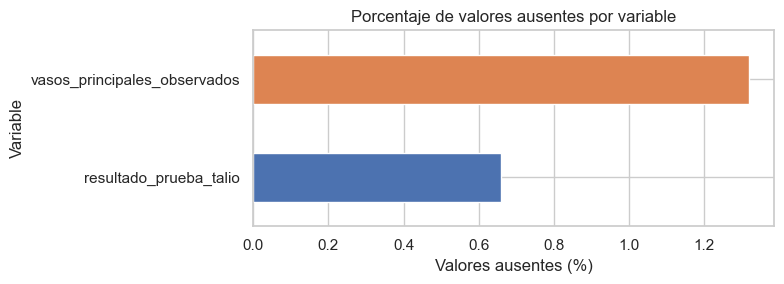

In [ ]:
ausencias_grafico = resumen_ausencias.loc[
    resumen_ausencias["valores_ausentes"] > 0
].sort_values("porcentaje_ausente")

if ausencias_grafico.empty:
    print("No se encontraron valores ausentes.")
else:
    eje = ausencias_grafico["porcentaje_ausente"].plot.barh(
        figsize=(8, max(3, 0.6 * len(ausencias_grafico))),
        color=sns.color_palette("deep", n_colors=len(ausencias_grafico)),
    )
    eje.set(
        title="Porcentaje de valores ausentes por variable",
        xlabel="Valores ausentes (%)",
        ylabel="Variable",
    )
    plt.tight_layout()
    plt.show()


## 7. Distribución del objetivo

El gráfico muestra las dos clases de `diagnostico_enfermedad_cardiaca`: 0 (sin enfermedad significativa) y 1 (enfermedad detectada; agrupa los códigos originales 1–4).


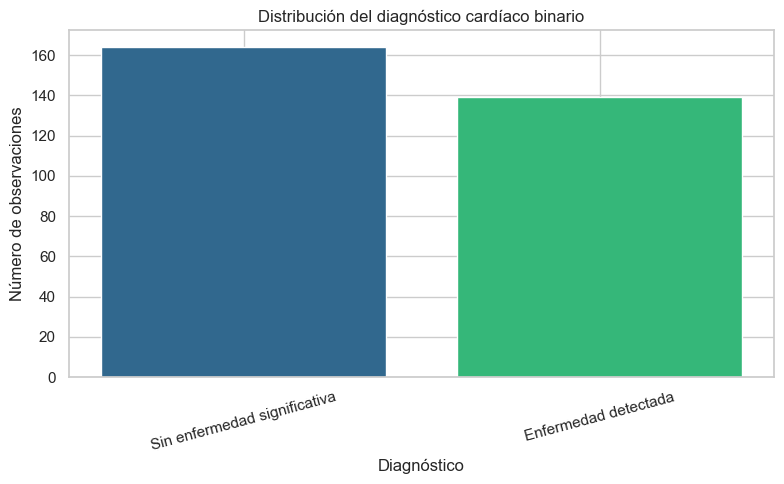

In [ ]:
conteo_diagnostico = (
    datos_procesados[columna_objetivo_espanol].value_counts().sort_index()
)
etiquetas_diagnostico = {
    0: "Sin enfermedad significativa",
    1: "Enfermedad detectada",
}

figura, eje = plt.subplots(figsize=(8, 5))
eje.bar(
    [etiquetas_diagnostico[codigo] for codigo in conteo_diagnostico.index],
    conteo_diagnostico.values,
    color=sns.color_palette("viridis", n_colors=len(conteo_diagnostico)),
)
eje.set(
    title="Distribución del diagnóstico cardíaco binario",
    xlabel="Diagnóstico",
    ylabel="Número de observaciones",
)
eje.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()


### Distribución de edad

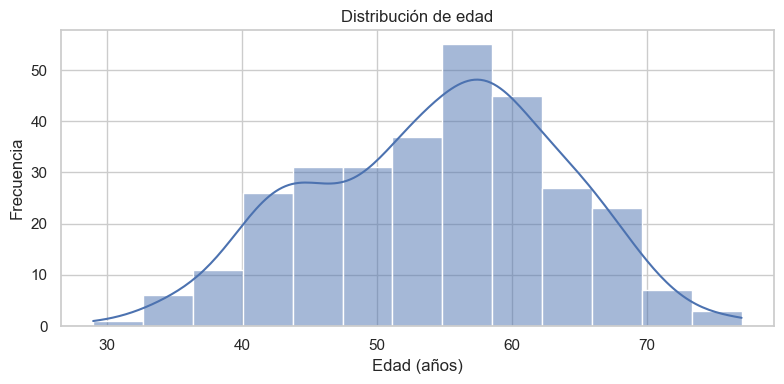

In [ ]:
valores_grafico = datos_codificados["edad"].dropna()
figura, eje = plt.subplots(figsize=(8, 4))
sns.histplot(valores_grafico, kde=valores_grafico.nunique() > 1, ax=eje)
eje.set(
    title="Distribución de edad",
    xlabel="Edad (años)",
    ylabel="Frecuencia",
)
plt.tight_layout()
plt.show()


### Distribución de presión arterial en reposo

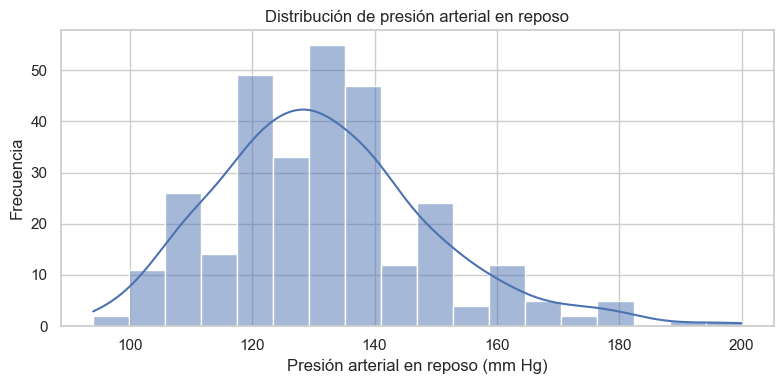

In [ ]:
valores_grafico = datos_codificados["presion_arterial_reposo"].dropna()
figura, eje = plt.subplots(figsize=(8, 4))
sns.histplot(valores_grafico, kde=valores_grafico.nunique() > 1, ax=eje)
eje.set(
    title="Distribución de presión arterial en reposo",
    xlabel="Presión arterial en reposo (mm Hg)",
    ylabel="Frecuencia",
)
plt.tight_layout()
plt.show()


### Distribución de colesterol sérico

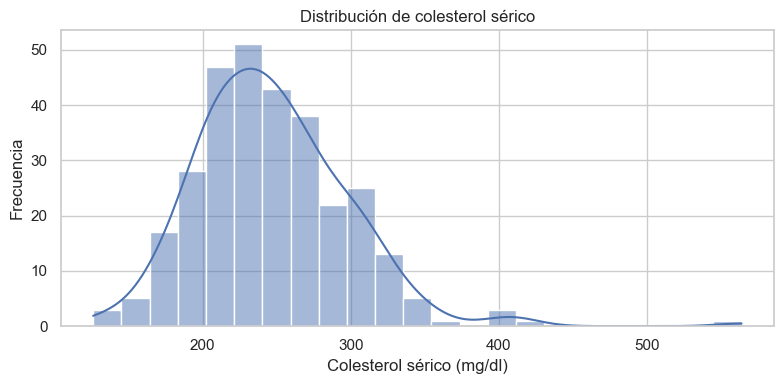

In [ ]:
valores_grafico = datos_codificados["colesterol_serico"].dropna()
figura, eje = plt.subplots(figsize=(8, 4))
sns.histplot(valores_grafico, kde=valores_grafico.nunique() > 1, ax=eje)
eje.set(
    title="Distribución de colesterol sérico",
    xlabel="Colesterol sérico (mg/dl)",
    ylabel="Frecuencia",
)
plt.tight_layout()
plt.show()


### Distribución de frecuencia cardíaca máxima

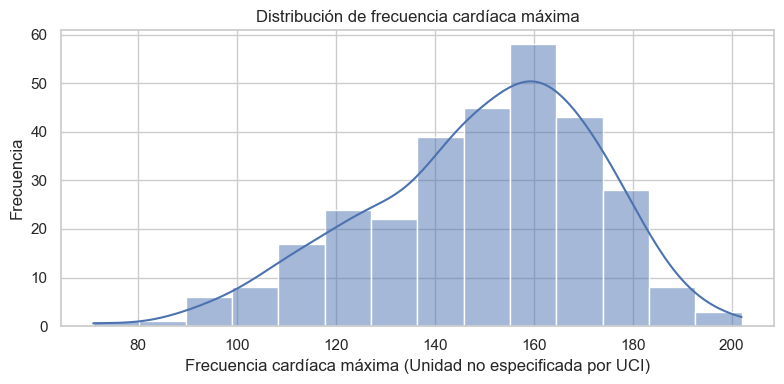

In [ ]:
valores_grafico = datos_codificados["frecuencia_cardiaca_maxima"].dropna()
figura, eje = plt.subplots(figsize=(8, 4))
sns.histplot(valores_grafico, kde=valores_grafico.nunique() > 1, ax=eje)
eje.set(
    title="Distribución de frecuencia cardíaca máxima",
    xlabel="Frecuencia cardíaca máxima (Unidad no especificada por UCI)",
    ylabel="Frecuencia",
)
plt.tight_layout()
plt.show()


### Distribución de depresión st durante el ejercicio

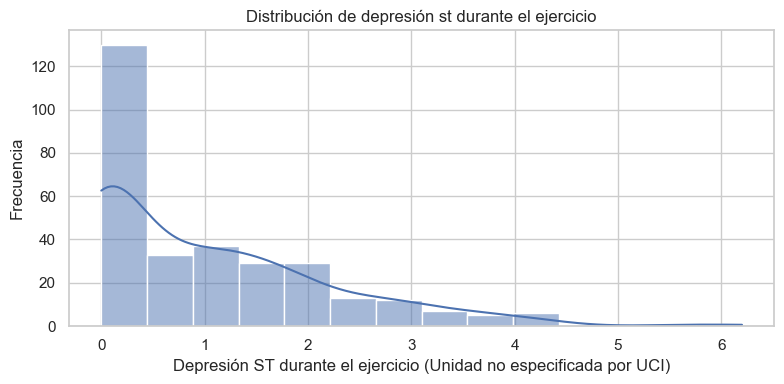

In [ ]:
valores_grafico = datos_codificados["depresion_st_ejercicio"].dropna()
figura, eje = plt.subplots(figsize=(8, 4))
sns.histplot(valores_grafico, kde=valores_grafico.nunique() > 1, ax=eje)
eje.set(
    title="Distribución de depresión st durante el ejercicio",
    xlabel="Depresión ST durante el ejercicio (Unidad no especificada por UCI)",
    ylabel="Frecuencia",
)
plt.tight_layout()
plt.show()


## 8. Diagramas de caja para revisar valores extremos

Los puntos fuera de los bigotes son candidatos a revisión, no errores por definición. Se presentan por separado para que cada variable tenga su propio gráfico.


### Valores de edad

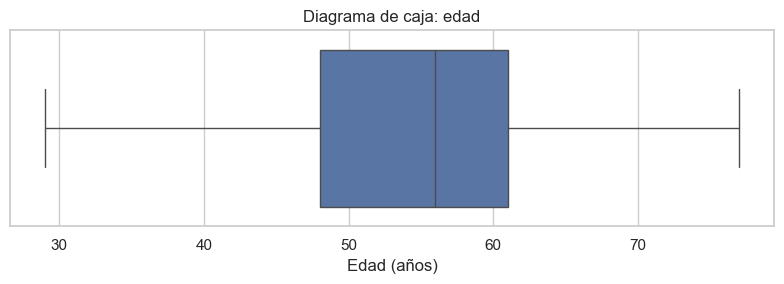

In [ ]:
figura, eje = plt.subplots(figsize=(8, 3))
sns.boxplot(x=datos_codificados["edad"], ax=eje, color=sns.color_palette("deep")[0])
eje.set(
    title="Diagrama de caja: edad",
    xlabel="Edad (años)",
)
plt.tight_layout()
plt.show()


### Valores de presión arterial en reposo

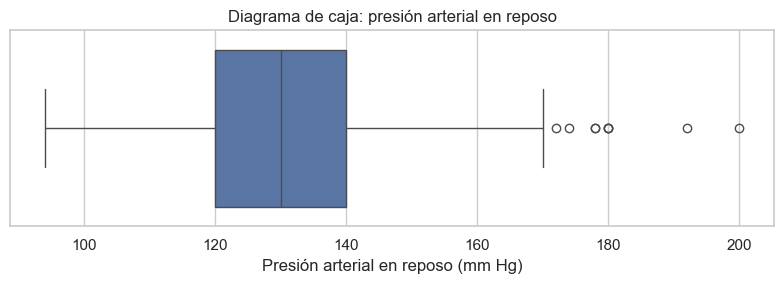

In [ ]:
figura, eje = plt.subplots(figsize=(8, 3))
sns.boxplot(x=datos_codificados["presion_arterial_reposo"], ax=eje, color=sns.color_palette("deep")[0])
eje.set(
    title="Diagrama de caja: presión arterial en reposo",
    xlabel="Presión arterial en reposo (mm Hg)",
)
plt.tight_layout()
plt.show()


### Valores de colesterol sérico

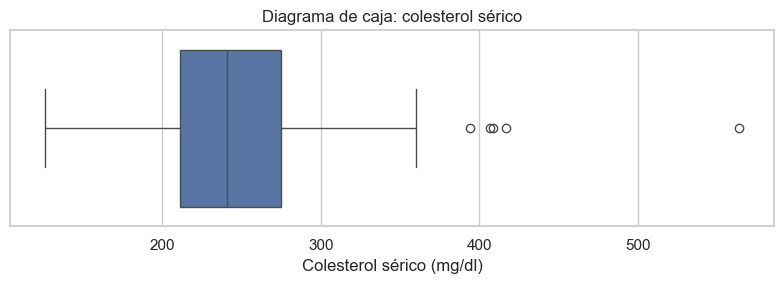

In [ ]:
figura, eje = plt.subplots(figsize=(8, 3))
sns.boxplot(x=datos_codificados["colesterol_serico"], ax=eje, color=sns.color_palette("deep")[0])
eje.set(
    title="Diagrama de caja: colesterol sérico",
    xlabel="Colesterol sérico (mg/dl)",
)
plt.tight_layout()
plt.show()


### Valores de frecuencia cardíaca máxima

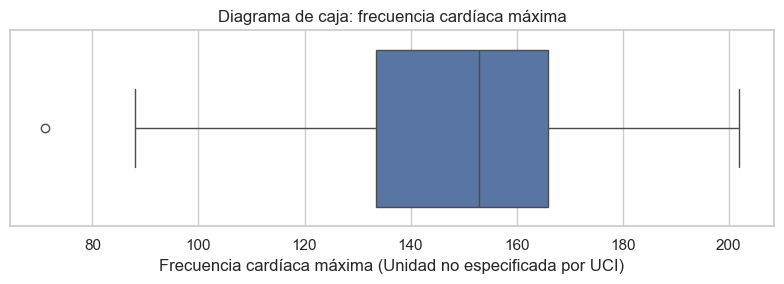

In [ ]:
figura, eje = plt.subplots(figsize=(8, 3))
sns.boxplot(x=datos_codificados["frecuencia_cardiaca_maxima"], ax=eje, color=sns.color_palette("deep")[0])
eje.set(
    title="Diagrama de caja: frecuencia cardíaca máxima",
    xlabel="Frecuencia cardíaca máxima (Unidad no especificada por UCI)",
)
plt.tight_layout()
plt.show()


### Valores de depresión st durante el ejercicio

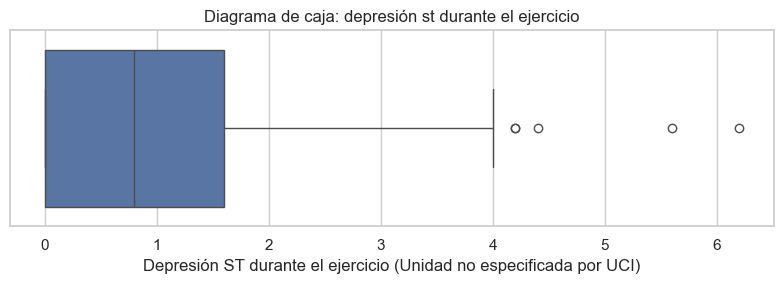

In [ ]:
figura, eje = plt.subplots(figsize=(8, 3))
sns.boxplot(x=datos_codificados["depresion_st_ejercicio"], ax=eje, color=sns.color_palette("deep")[0])
eje.set(
    title="Diagrama de caja: depresión st durante el ejercicio",
    xlabel="Depresión ST durante el ejercicio (Unidad no especificada por UCI)",
)
plt.tight_layout()
plt.show()


## 9. Frecuencias de variables categóricas

Las gráficas usan etiquetas españolas verificadas frente a los códigos presentes en la descarga. `ca` se trata aparte como recuento discreto, no como una categoría nominal.


### Frecuencia: sexo

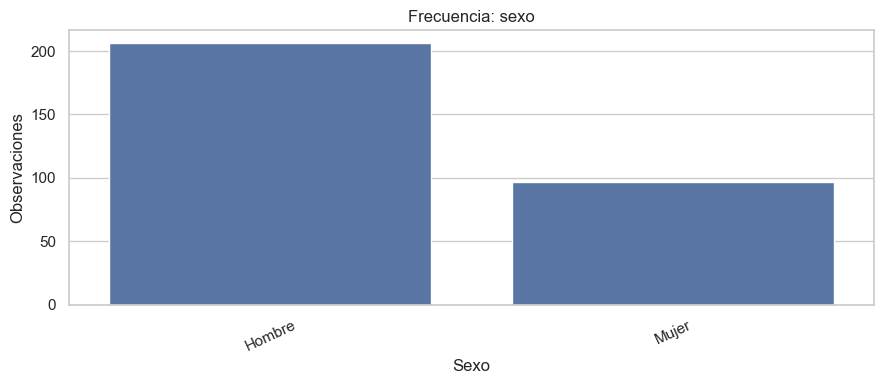

In [ ]:
orden_categorias = datos_procesados["sexo"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="sexo",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: sexo", xlabel="Sexo", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: tipo de dolor torácico

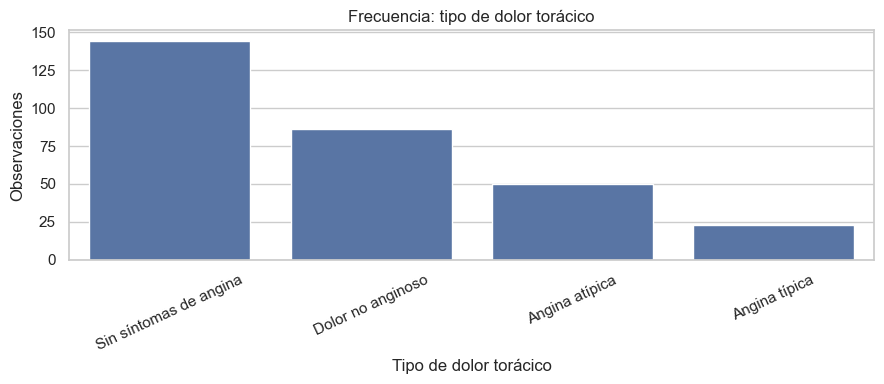

In [ ]:
orden_categorias = datos_procesados["tipo_dolor_toracico"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="tipo_dolor_toracico",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: tipo de dolor torácico", xlabel="Tipo de dolor torácico", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: glucosa en ayunas

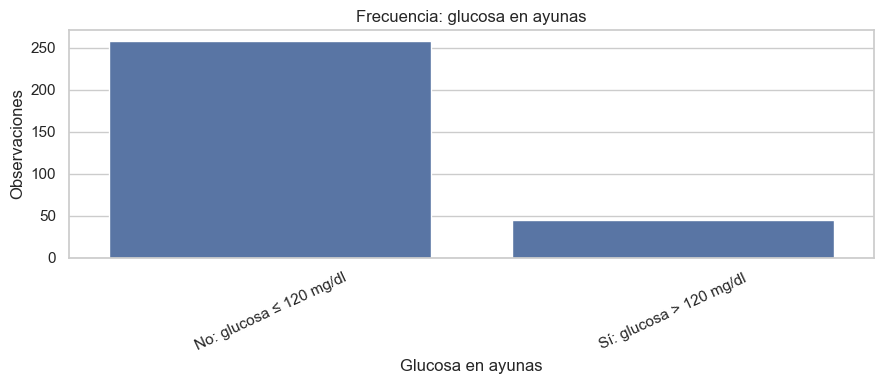

In [ ]:
orden_categorias = datos_procesados["glucosa_ayunas_alta"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="glucosa_ayunas_alta",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: glucosa en ayunas", xlabel="Glucosa en ayunas", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: electrocardiograma en reposo

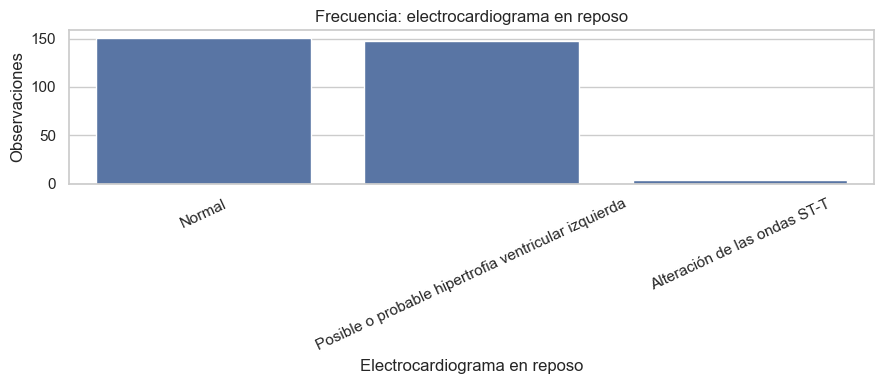

In [ ]:
orden_categorias = datos_procesados["resultado_electrocardiograma_reposo"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="resultado_electrocardiograma_reposo",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: electrocardiograma en reposo", xlabel="Electrocardiograma en reposo", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: angina inducida por ejercicio

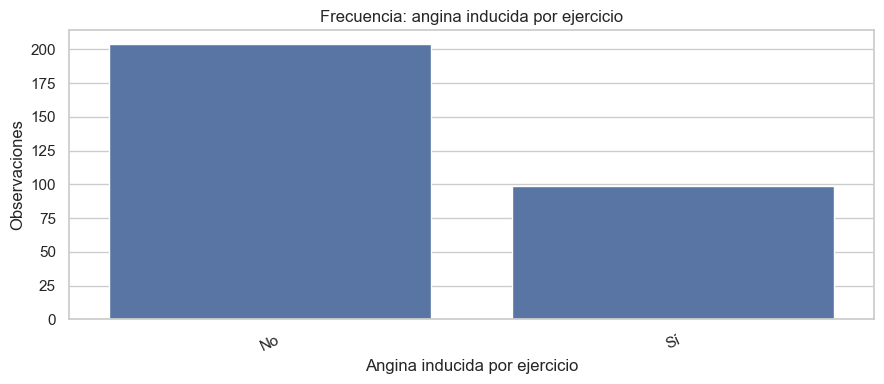

In [ ]:
orden_categorias = datos_procesados["angina_inducida_ejercicio"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="angina_inducida_ejercicio",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: angina inducida por ejercicio", xlabel="Angina inducida por ejercicio", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: pendiente del segmento st

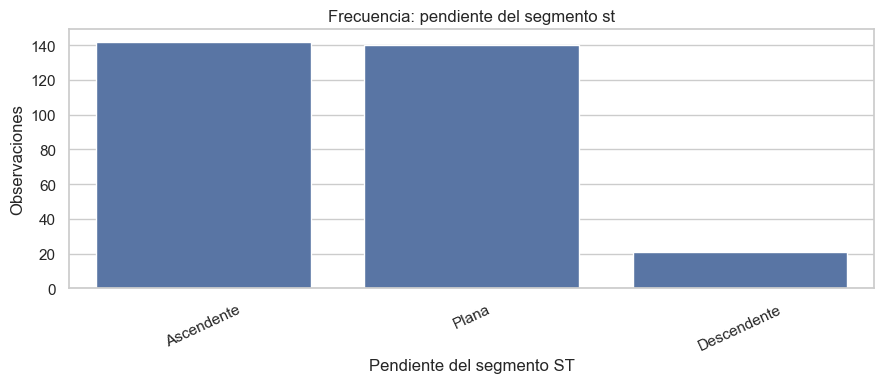

In [ ]:
orden_categorias = datos_procesados["pendiente_segmento_st"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="pendiente_segmento_st",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: pendiente del segmento st", xlabel="Pendiente del segmento ST", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia: resultado de la prueba de talio

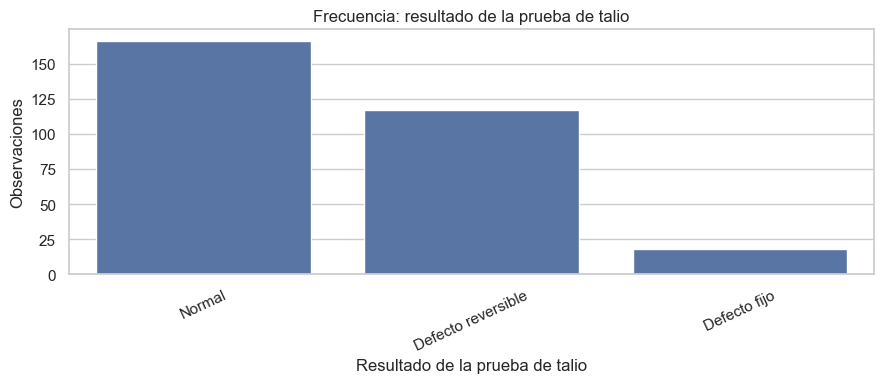

In [ ]:
orden_categorias = datos_procesados["resultado_prueba_talio"].value_counts().index
figura, eje = plt.subplots(figsize=(9, 4))
sns.countplot(
    data=datos_procesados,
    x="resultado_prueba_talio",
    order=orden_categorias,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(title="Frecuencia: resultado de la prueba de talio", xlabel="Resultado de la prueba de talio", ylabel="Observaciones")
eje.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


### Frecuencia del recuento de vasos observados

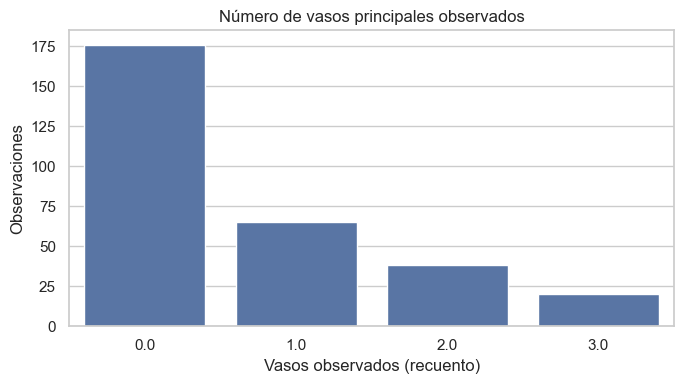

In [ ]:
orden_vasos = sorted(datos_originales["ca"].dropna().unique())
figura, eje = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=datos_originales,
    x="ca",
    order=orden_vasos,
    ax=eje,
    color=sns.color_palette("deep")[0],
)
eje.set(
    title="Número de vasos principales observados",
    xlabel="Vasos observados (recuento)",
    ylabel="Observaciones",
)
plt.tight_layout()
plt.show()


## 10. Correlación entre variables cuantitativas

Se usa Spearman como asociación monotónica exploratoria. Una correlación no implica causalidad; las variables con valores ausentes se calculan por pares disponibles y no se imputan.


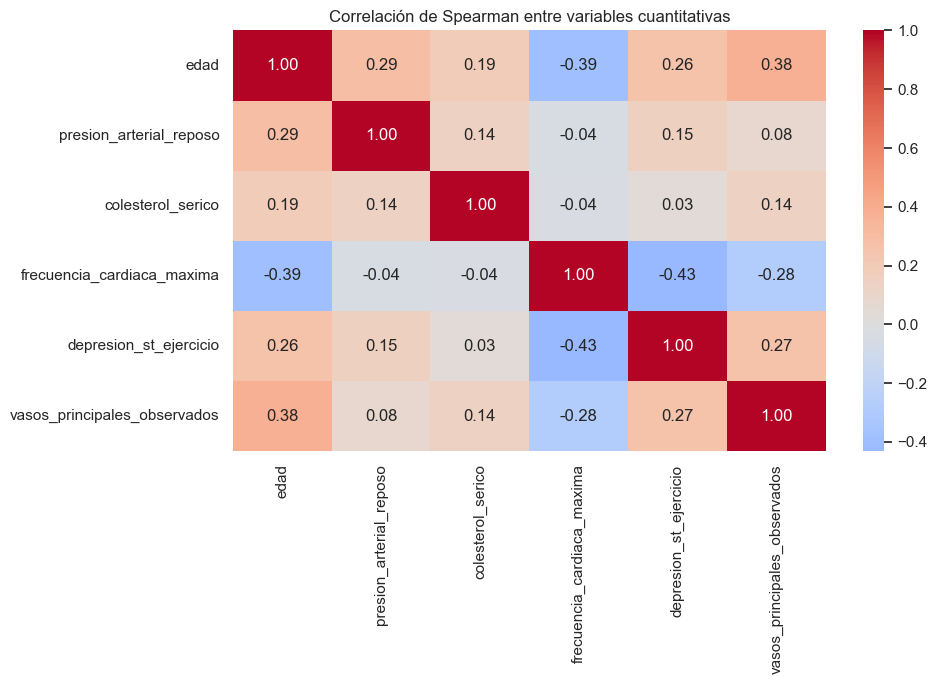

In [ ]:
columnas_correlacion = [
    "edad",
    "presion_arterial_reposo",
    "colesterol_serico",
    "frecuencia_cardiaca_maxima",
    "depresion_st_ejercicio",
    "vasos_principales_observados",
]
matriz_correlacion = datos_codificados[columnas_correlacion].corr(
    method="spearman"
)
figura, eje = plt.subplots(figsize=(10, 7))
sns.heatmap(
    matriz_correlacion,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    ax=eje,
)
eje.set_title("Correlación de Spearman entre variables cuantitativas")
plt.tight_layout()
plt.show()


## 11. Interpretación para la siguiente fase de Machine Learning

- La matriz original y la vista procesada conservan 303 filas; `ca` y `thal` siguen teniendo sus ausencias.
- El objetivo para clasificación es binario en `datos_procesados`: 0 = sin enfermedad significativa; 1 = códigos UCI originales 1–4, enfermedad detectada. `datos_originales["num"]` conserva los códigos fuente para trazabilidad.
- No hay identificadores ni variables marcadas como irrelevantes entre las 13 características publicadas para este conjunto.
- No uses los códigos de variables categóricas como si fueran cantidades continuas. En la fase de modelado se deben tratar como categóricas (por ejemplo, mediante codificación dentro de un `Pipeline`) y definir una estrategia de imputación de `ca` y `thal` usando solo los datos de entrenamiento.
- La ficha suministrada enumera `oldpeak` como entero, pero la descarga observada contiene decimales; se documenta como continua de acuerdo con los valores y la descripción de la variable.


## 12. Separación de datos y pipeline sin fuga de información

Se reserva el 20 % de los datos para test mediante muestreo estratificado y semilla 56. El test no se usa para seleccionar categorías, imputar, escalar, entrenar ni validar. Las filas de entrenamiento y test se conservan sin transformar.

El preprocesamiento se integra en el pipeline. Las cinco variables cuantitativas (`edad`, `presion_arterial_reposo`, `colesterol_serico`, `frecuencia_cardiaca_maxima` y `depresion_st_ejercicio`) se imputan por mediana y se transforman con `StandardScaler` (media 0 y desviación estándar 1). Las ocho variables categóricas, incluido el recuento `vasos_principales_observados`, se imputan por moda y se codifican con One-Hot Encoding para no imponer un orden a sus códigos.

El escalador aprende sus parámetros solo del conjunto de ajuste: en cada fold, la validación cruzada clona y ajusta el pipeline sin usar las observaciones de validación de ese fold. En el ajuste final, el test sigue separado y solo se transforma con los parámetros aprendidos en entrenamiento. `ca` y `thal` mantienen sus nulos en los datos crudos; la imputación se aprende dentro de cada ajuste.

El Random Forest final es un modelo de árboles y no necesita escalar variables para dividirlas: una transformación lineal monótona como `StandardScaler` conserva el orden de los valores. Se mantiene este paso porque el pipeline también se utiliza para la regresión logística baseline, para la que la escala sí puede afectar al ajuste, y así todos los candidatos comparten el mismo preprocesamiento sin fuga. El formulario recibe siempre los valores en sus unidades originales; el escalado ocurre dentro del pipeline.

El clasificador logístico se usa como baseline. No se evalúa contra el test en esta etapa.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

caracteristicas = (
    datos_originales
    .drop(columns="num")
    .rename(columns=nombres_en_espanol)
    .copy(deep=True)
)
objetivo = (
    datos_originales["num"]
    .gt(0)
    .astype("int8")
    .rename("diagnostico_enfermedad_cardiaca")
)

if not caracteristicas.index.equals(objetivo.index):
    raise ValueError("Los índices de características y objetivo no coinciden.")
if objetivo.isna().any() or set(objetivo.unique()) != {0, 1}:
    raise ValueError("El objetivo debe contener únicamente las clases binarias 0 y 1.")

variables_cuantitativas = [
    "edad",
    "presion_arterial_reposo",
    "colesterol_serico",
    "frecuencia_cardiaca_maxima",
    "depresion_st_ejercicio",
]
variables_categoricas = [
    "sexo",
    "tipo_dolor_toracico",
    "glucosa_ayunas_alta",
    "resultado_electrocardiograma_reposo",
    "angina_inducida_ejercicio",
    "pendiente_segmento_st",
    "vasos_principales_observados",
    "resultado_prueba_talio",
]
if set(variables_cuantitativas + variables_categoricas) != set(caracteristicas.columns):
    raise ValueError("Las variables del preprocesamiento no coinciden con las características.")

caracteristicas_entrenamiento, caracteristicas_test, objetivo_entrenamiento, objetivo_test = (
    train_test_split(
        caracteristicas,
        objetivo,
        test_size=0.20,
        random_state=SEMILLA,
        stratify=objetivo,
    )
)

imputador_y_escalador_numerico = Pipeline(
    steps=[
        ("imputador_mediana", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler()),
    ]
)
imputador_y_codificador_categorico = Pipeline(
    steps=[
        ("imputador_moda", SimpleImputer(strategy="most_frequent")),
        ("one_hot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", imputador_y_escalador_numerico, variables_cuantitativas),
        ("categoricas", imputador_y_codificador_categorico, variables_categoricas),
    ],
    remainder="drop",
)
pipeline_modelado = Pipeline(
    steps=[
        ("preprocesamiento", preprocesador),
        ("clasificador", LogisticRegression(max_iter=2_000, random_state=SEMILLA)),
    ]
)

validador_cruzado = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=SEMILLA,
)
particiones_entrenamiento = list(
    validador_cruzado.split(caracteristicas_entrenamiento, objetivo_entrenamiento)
)

print(f"Entrenamiento: {len(caracteristicas_entrenamiento)} filas")
print(f"Test reservado: {len(caracteristicas_test)} filas")
print("\nDistribución de clases en entrenamiento:")
display(
    objetivo_entrenamiento.value_counts()
    .sort_index()
    .rename(index={0: "Sin enfermedad", 1: "Enfermedad detectada"})
    .to_frame("observaciones")
)
print("\nDistribución de clases en test (solo comprobación descriptiva; no se usa para ajustar):")
display(
    objetivo_test.value_counts()
    .sort_index()
    .rename(index={0: "Sin enfermedad", 1: "Enfermedad detectada"})
    .to_frame("observaciones")
)
print("\nTamaño de entrenamiento y validación por fold (solo dentro del entrenamiento):")
resumen_particiones = []
for numero_pliegue, (indices_ajuste, indices_validacion) in enumerate(
    particiones_entrenamiento, start=1
):
    resumen_particiones.append(
        {
            "pliegue": numero_pliegue,
            "filas_ajuste": len(indices_ajuste),
            "filas_validacion": len(indices_validacion),
            "positivos_ajuste": int(objetivo_entrenamiento.iloc[indices_ajuste].sum()),
            "positivos_validacion": int(objetivo_entrenamiento.iloc[indices_validacion].sum()),
        }
    )
display(pd.DataFrame(resumen_particiones).set_index("pliegue"))

print(
    "\nSe conservan para uso posterior: caracteristicas_entrenamiento, "
    "caracteristicas_test, objetivo_entrenamiento, objetivo_test, "
    "preprocesador, pipeline_modelado y particiones_entrenamiento."
)
print(
    "Las matrices se mantienen crudas: no se ha ajustado el preprocesador "
    "ni se ha transformado el conjunto test."
)


Entrenamiento: 242 filas
Test reservado: 61 filas

Distribución de clases en entrenamiento:


,observaciones
diagnostico_enfermedad_cardiaca,
Sin enfermedad,131
Enfermedad detectada,111



Distribución de clases en test (solo comprobación descriptiva; no se usa para ajustar):


,observaciones
diagnostico_enfermedad_cardiaca,
Sin enfermedad,33
Enfermedad detectada,28



Tamaño de entrenamiento y validación por fold (solo dentro del entrenamiento):


,filas_ajuste,filas_validacion,positivos_ajuste,positivos_validacion
pliegue,,,,
1,181,61,83,28
2,181,61,83,28
3,182,60,84,27
4,182,60,83,28



Se conservan para uso posterior: caracteristicas_entrenamiento, caracteristicas_test, objetivo_entrenamiento, objetivo_test, preprocesador, pipeline_modelado y particiones_entrenamiento.
Las matrices se mantienen crudas: no se ha ajustado el preprocesador ni se ha transformado el conjunto test.


## 13. Validación cruzada del baseline (solo entrenamiento)

Se calculan métricas en los cuatro folds con un pipeline completo. El test reservado no participa en estas métricas ni en el ajuste.

In [ ]:
metricas_validacion = {
    "exactitud_balanceada": "balanced_accuracy",
    "precision": "precision",
    "sensibilidad": "recall",
    "f1": "f1",
    "auc_roc": "roc_auc",
}

resultados_validacion = cross_validate(
    estimator=pipeline_modelado,
    X=caracteristicas_entrenamiento,
    y=objetivo_entrenamiento,
    cv=particiones_entrenamiento,
    scoring=metricas_validacion,
    return_train_score=False,
    n_jobs=None,
    error_score="raise",
)

resumen_validacion = pd.DataFrame(
    {
        nombre_metrica: resultados_validacion[f"test_{nombre_metrica}"]
        for nombre_metrica in metricas_validacion
    },
    index=[f"Pliegue {numero}" for numero in range(1, len(particiones_entrenamiento) + 1)],
)
resumen_validacion.loc["Media"] = resumen_validacion.mean()
resumen_validacion.loc["Desviación estándar"] = resumen_validacion.iloc[:-1].std(ddof=1)
display(resumen_validacion)

print(
    "Estas métricas son solo de validación cruzada en entrenamiento. "
    "El conjunto test sigue reservado para la evaluación final tras elegir "
    "el modelo y cerrar el ajuste."
)


,exactitud_balanceada,precision,sensibilidad,f1,auc_roc
Pliegue 1,0.81,0.84,0.75,0.79,0.91
Pliegue 2,0.85,0.85,0.82,0.84,0.93
Pliegue 3,0.78,0.75,0.78,0.76,0.86
Pliegue 4,0.85,0.85,0.82,0.84,0.91
Media,0.82,0.82,0.79,0.81,0.90
Desviación estándar,0.03,0.05,0.04,0.04,0.03


Estas métricas son solo de validación cruzada en entrenamiento. El conjunto test sigue reservado para la evaluación final tras elegir el modelo y cerrar el ajuste.


## 14. Random Forest: búsqueda exhaustiva de hiperparámetros

Se evalúan **144 combinaciones** con validación cruzada estratificada de 4 folds (576 ajustes). La selección y el top 2 se ordenan por **precisión media** en los folds; también se registran exactitud balanceada, ROC-AUC, sensibilidad y F1. La búsqueda y el reajuste de la mejor configuración usan solo entrenamiento. El test no interviene.

La rejilla cubre número de árboles, profundidad, tamaño mínimo de hojas y divisiones, número de variables por división y ponderación de clases. La precisión prioriza evitar falsos positivos; también revisamos la sensibilidad porque en salud los falsos negativos pueden ser especialmente costosos. La optimización usa el umbral de clasificación predeterminado; ajustar umbral requiere validación adicional solo dentro del entrenamiento. Las métricas de los mejores candidatos pueden ser optimistas por selección.


In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

metricas_busqueda = {
    "roc_auc": "roc_auc",
    "exactitud_balanceada": "balanced_accuracy",
    "precision": "precision",
    "sensibilidad": "recall",
    "f1": "f1",
}

pipeline_random_forest = clone(pipeline_modelado).set_params(
    clasificador=RandomForestClassifier(
        random_state=SEMILLA,
        n_jobs=1,
    )
)

rejilla_random_forest = {
    "clasificador__n_estimators": [200, 400],
    "clasificador__max_depth": [None, 4, 8],
    "clasificador__min_samples_split": [2, 5],
    "clasificador__min_samples_leaf": [1, 2, 4],
    "clasificador__max_features": ["sqrt", 0.75],
    "clasificador__class_weight": [None, "balanced"],
}

busqueda_random_forest = GridSearchCV(
    estimator=pipeline_random_forest,
    param_grid=rejilla_random_forest,
    scoring=metricas_busqueda,
    refit="precision",
    cv=particiones_entrenamiento,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise",
)
busqueda_random_forest.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)
modelo_random_forest_optimizado = busqueda_random_forest.best_estimator_

resultados_rf = pd.DataFrame(busqueda_random_forest.cv_results_)
columnas_parametros_rf = [
    columna for columna in resultados_rf.columns if columna.startswith("param_")
]
columnas_metricas_rf = [
    nombre
    for metrica in metricas_busqueda
    for nombre in (f"mean_test_{metrica}", f"std_test_{metrica}")
]
mejores_dos_random_forest = (
    resultados_rf
    .sort_values("mean_test_precision", ascending=False)
    .head(2)[columnas_parametros_rf + columnas_metricas_rf]
    .reset_index(drop=True)
)
mejores_dos_random_forest.index = ["Mejor configuración", "Segunda mejor configuración"]
if "param_clasificador__class_weight" in mejores_dos_random_forest:
    mejores_dos_random_forest["param_clasificador__class_weight"] = (
        mejores_dos_random_forest["param_clasificador__class_weight"]
        .astype(object)
        .where(mejores_dos_random_forest["param_clasificador__class_weight"].notna(), "Sin ponderación (None)")
    )
if "param_clasificador__max_depth" in mejores_dos_random_forest:
    mejores_dos_random_forest["param_clasificador__max_depth"] = (
        mejores_dos_random_forest["param_clasificador__max_depth"]
        .astype(object)
        .where(mejores_dos_random_forest["param_clasificador__max_depth"].notna(), "Sin límite (None)")
    )

print(f"Combinaciones probadas: {len(resultados_rf)}")
print("Criterio principal de selección: precisión media en validación cruzada (4 folds).")
print("Mejores dos configuraciones y métricas (media y desviación estándar entre folds):")
display(mejores_dos_random_forest)
print("\nMejores hiperparámetros, reajustados solo con todo el entrenamiento:")
display(pd.Series(busqueda_random_forest.best_params_, name="valor"))


Combinaciones probadas: 144
Criterio principal de selección: precisión media en validación cruzada (4 folds).
Mejores dos configuraciones y métricas (media y desviación estándar entre folds):


,param_clasificador__class_weight,param_clasificador__max_depth,param_clasificador__max_features,param_clasificador__min_samples_leaf,param_clasificador__min_samples_split,param_clasificador__n_estimators,mean_test_roc_auc,std_test_roc_auc,mean_test_exactitud_balanceada,std_test_exactitud_balanceada,mean_test_precision,std_test_precision,mean_test_sensibilidad,std_test_sensibilidad,mean_test_f1,std_test_f1
Mejor configuración,Sin ponderación (None),4,sqrt,2,5,200,0.90,0.03,0.84,0.05,0.86,0.08,0.80,0.04,0.83,0.05
Segunda mejor configuración,Sin ponderación (None),4,sqrt,1,5,200,0.90,0.03,0.84,0.05,0.85,0.09,0.81,0.03,0.83,0.06



Mejores hiperparámetros, reajustados solo con todo el entrenamiento:


clasificador__class_weight         None
clasificador__max_depth               4
clasificador__max_features         sqrt
clasificador__min_samples_leaf        2
clasificador__min_samples_split       5
clasificador__n_estimators          200
Name: valor, dtype: object

## 15. XGBoost: búsqueda exhaustiva de hiperparámetros

Se evalúan **864 combinaciones** con los mismos 4 folds y las mismas métricas que Random Forest (3.456 ajustes). La selección y el top 2 se ordenan por **precisión media** en los folds; se informan también exactitud balanceada, ROC-AUC, sensibilidad y F1. La rejilla recorre número de árboles, profundidad, tasa de aprendizaje, peso mínimo de hoja, muestreo de filas y columnas, regularización L2 y gamma. Se limita XGBoost a un hilo por ajuste para evitar sobrecargar el paralelismo exterior de GridSearchCV.

El preprocesamiento está dentro del pipeline, por lo que se aprende de nuevo en cada fold. Se informa el top 2 por ROC-AUC medio; el test sigue reservado y no se usa para elegir modelo ni hiperparámetros.


In [ ]:
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from xgboost import XGBClassifier

pipeline_xgboost = clone(pipeline_modelado).set_params(
    clasificador=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=SEMILLA,
        n_jobs=1,
        verbosity=0,
    )
)

rejilla_xgboost = {
    "clasificador__n_estimators": [100, 250, 500],
    "clasificador__max_depth": [2, 3, 4],
    "clasificador__learning_rate": [0.03, 0.07, 0.1],
    "clasificador__min_child_weight": [1, 3],
    "clasificador__subsample": [0.8, 1.0],
    "clasificador__colsample_bytree": [0.8, 1.0],
    "clasificador__reg_lambda": [1, 5],
    "clasificador__gamma": [0, 0.25],
}

busqueda_xgboost = GridSearchCV(
    estimator=pipeline_xgboost,
    param_grid=rejilla_xgboost,
    scoring=metricas_busqueda,
    refit="precision",
    cv=particiones_entrenamiento,
    n_jobs=-1,
    return_train_score=False,
    error_score="raise",
)
busqueda_xgboost.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)
modelo_xgboost_optimizado = busqueda_xgboost.best_estimator_

resultados_xgb = pd.DataFrame(busqueda_xgboost.cv_results_)
columnas_parametros_xgb = [
    columna for columna in resultados_xgb.columns if columna.startswith("param_")
]
columnas_metricas_xgb = [
    nombre
    for metrica in metricas_busqueda
    for nombre in (f"mean_test_{metrica}", f"std_test_{metrica}")
]
mejores_dos_xgboost = (
    resultados_xgb
    .sort_values("mean_test_precision", ascending=False)
    .head(2)[columnas_parametros_xgb + columnas_metricas_xgb]
    .reset_index(drop=True)
)
mejores_dos_xgboost.index = ["Mejor configuración", "Segunda mejor configuración"]

print(f"Combinaciones probadas: {len(resultados_xgb)}")
print("Criterio principal de selección: precisión media en validación cruzada (4 folds).")
print("Mejores dos configuraciones y métricas (media y desviación estándar entre folds):")
display(mejores_dos_xgboost)
print("\nMejores hiperparámetros, reajustados solo con todo el entrenamiento:")
display(pd.Series(busqueda_xgboost.best_params_, name="valor"))


Combinaciones probadas: 864
Criterio principal de selección: precisión media en validación cruzada (4 folds).
Mejores dos configuraciones y métricas (media y desviación estándar entre folds):


,param_clasificador__colsample_bytree,param_clasificador__gamma,param_clasificador__learning_rate,param_clasificador__max_depth,param_clasificador__min_child_weight,param_clasificador__n_estimators,param_clasificador__reg_lambda,param_clasificador__subsample,mean_test_roc_auc,std_test_roc_auc,mean_test_exactitud_balanceada,std_test_exactitud_balanceada,mean_test_precision,std_test_precision,mean_test_sensibilidad,std_test_sensibilidad,mean_test_f1,std_test_f1
Mejor configuración,1.00,0.00,0.03,2,1,250,1,0.80,0.88,0.04,0.81,0.04,0.83,0.05,0.77,0.04,0.79,0.04
Segunda mejor configuración,1.00,0.25,0.03,2,1,250,1,0.80,0.88,0.04,0.81,0.04,0.83,0.05,0.77,0.04,0.79,0.04



Mejores hiperparámetros, reajustados solo con todo el entrenamiento:


clasificador__colsample_bytree     1.00
clasificador__gamma                0.00
clasificador__learning_rate        0.03
clasificador__max_depth            2.00
clasificador__min_child_weight     1.00
clasificador__n_estimators       250.00
clasificador__reg_lambda           1.00
clasificador__subsample            0.80
Name: valor, dtype: float64

## 16. Comparación: baseline, Random Forest y XGBoost optimizados

Comparamos las métricas medias de validación cruzada del baseline logístico con los mejores candidatos de cada búsqueda. Random Forest y XGBoost se seleccionan por precisión media en los mismos folds. Las desviaciones estándar muestran variación entre pliegues.

**No se incluyen métricas de test todavía:** el test queda apartado para la evaluación final del modelo seleccionado. La precisión es la proporción de predicciones positivas que son verdaderos positivos y ayuda a limitar falsos positivos; no debe optimizarse ignorando sensibilidad, que mide cuántos casos con enfermedad detectamos. Las métricas de GridSearchCV pueden sobreestimar el rendimiento por la selección entre configuraciones y no equivalen a una evaluación independiente.


In [ ]:
resumen_modelos = pd.DataFrame(
    {
        "ROC-AUC media CV": [
            resultados_validacion["test_auc_roc"].mean(),
            resultados_rf.loc[
                busqueda_random_forest.best_index_, "mean_test_roc_auc"
            ],
            resultados_xgb.loc[
                busqueda_xgboost.best_index_, "mean_test_roc_auc"
            ],
        ],
        "ROC-AUC desviación estándar CV": [
            resultados_validacion["test_auc_roc"].std(ddof=1),
            resultados_rf.loc[
                busqueda_random_forest.best_index_, "std_test_roc_auc"
            ],
            resultados_xgb.loc[
                busqueda_xgboost.best_index_, "std_test_roc_auc"
            ],
        ],
        "Exactitud balanceada media CV": [
            resultados_validacion["test_exactitud_balanceada"].mean(),
            resultados_rf.loc[
                busqueda_random_forest.best_index_, "mean_test_exactitud_balanceada"
            ],
            resultados_xgb.loc[
                busqueda_xgboost.best_index_, "mean_test_exactitud_balanceada"
            ],
        ],
        "Precisión media CV": [
            resultados_validacion["test_precision"].mean(),
            resultados_rf.loc[
                busqueda_random_forest.best_index_, "mean_test_precision"
            ],
            resultados_xgb.loc[
                busqueda_xgboost.best_index_, "mean_test_precision"
            ],
        ],
        "Sensibilidad media CV": [
            resultados_validacion["test_sensibilidad"].mean(),
            resultados_rf.loc[
                busqueda_random_forest.best_index_, "mean_test_sensibilidad"
            ],
            resultados_xgb.loc[
                busqueda_xgboost.best_index_, "mean_test_sensibilidad"
            ],
        ],
        "F1 media CV": [
            resultados_validacion["test_f1"].mean(),
            resultados_rf.loc[busqueda_random_forest.best_index_, "mean_test_f1"],
            resultados_xgb.loc[busqueda_xgboost.best_index_, "mean_test_f1"],
        ],
    },
    index=["Baseline: regresión logística", "Random Forest optimizado", "XGBoost optimizado"],
)
display(resumen_modelos.round(3))

mejor_modelo_cv = resumen_modelos.loc[
    ["Random Forest optimizado", "XGBoost optimizado"],
    "Precisión media CV",
].idxmax()
print(f"Mejor bosque según precisión media de CV: {mejor_modelo_cv}")
print(
    "Random Forest y XGBoost se comparan por precisión media de CV; el baseline "
    "se muestra como referencia. Esta selección usa solo entrenamiento; "
    "el conjunto test sigue reservado."
)


,ROC-AUC media CV,ROC-AUC desviación estándar CV,Exactitud balanceada media CV,Precisión media CV,Sensibilidad media CV,F1 media CV
Baseline: regresión logística,0.90,0.03,0.82,0.82,0.79,0.81
Random Forest optimizado,0.90,0.03,0.84,0.86,0.80,0.83
XGBoost optimizado,0.88,0.04,0.81,0.83,0.77,0.79


Mejor bosque según precisión media de CV: Random Forest optimizado
Random Forest y XGBoost se comparan por precisión media de CV; el baseline se muestra como referencia. Esta selección usa solo entrenamiento; el conjunto test sigue reservado.


## 17. Evaluación final en test

Una vez seleccionados los modelos con validación cruzada, se evalúan una sola vez sobre el conjunto test reservado. La regresión logística se ajusta solo con `caracteristicas_entrenamiento`; Random Forest y XGBoost usan los mejores `GridSearchCV.best_estimator_`, ya reajustados sobre el entrenamiento completo. Se pasan las filas crudas a cada pipeline: sus transformaciones ajustadas con entrenamiento se aplican a test sin volver a ajustarse.

Se informa precisión (métrica principal solicitada), sensibilidad, F1, exactitud balanceada, ROC-AUC y matriz de confusión. En un problema clínico, alta precisión reduce falsos positivos, pero no asegura detectar todos los casos: revisa especialmente sensibilidad y falsos negativos. Estas métricas de test no deben utilizarse para cambiar hiperparámetros o umbrales.


In [ ]:
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

modelo_logistico_test = clone(pipeline_modelado)
modelo_logistico_test.fit(caracteristicas_entrenamiento, objetivo_entrenamiento)

modelos_evaluacion = {
    "Regresión logística (baseline)": modelo_logistico_test,
    "Random Forest optimizado": modelo_random_forest_optimizado,
    "XGBoost optimizado": modelo_xgboost_optimizado,
}
resultados_test = {}
filas_metricas_test = []
etiquetas_clase = [0, 1]
nombres_clase = ["Sin enfermedad", "Enfermedad detectada"]

for nombre_modelo, modelo in modelos_evaluacion.items():
    prediccion = modelo.predict(caracteristicas_test)
    probabilidades = modelo.predict_proba(caracteristicas_test)[:, 1]
    matriz = confusion_matrix(objetivo_test, prediccion, labels=etiquetas_clase)
    verdaderos_negativos, falsos_positivos, falsos_negativos, verdaderos_positivos = (
        matriz.ravel()
    )

    resultados_test[nombre_modelo] = {
        "modelo": modelo,
        "predicciones": prediccion,
        "probabilidades_positivas": probabilidades,
        "matriz_confusion": matriz,
    }
    filas_metricas_test.append(
        {
            "modelo": nombre_modelo,
            "precision": precision_score(objetivo_test, prediccion, zero_division=0),
            "sensibilidad": recall_score(objetivo_test, prediccion, zero_division=0),
            "especificidad": (
                verdaderos_negativos / (verdaderos_negativos + falsos_positivos)
                if verdaderos_negativos + falsos_positivos
                else 0.0
            ),
            "f1": f1_score(objetivo_test, prediccion, zero_division=0),
            "exactitud_balanceada": balanced_accuracy_score(objetivo_test, prediccion),
            "auc_roc": roc_auc_score(objetivo_test, probabilidades),
        }
    )

    print(f"\n{nombre_modelo} — matriz de confusión (filas = real; columnas = predicho)")
    display(
        pd.DataFrame(
            matriz,
            index=[f"Real: {nombre}" for nombre in nombres_clase],
            columns=[f"Predicho: {nombre}" for nombre in nombres_clase],
        )
    )
    print(
        f"TN={verdaderos_negativos} (negativos correctos), "
        f"FP={falsos_positivos} (falsos positivos), "
        f"FN={falsos_negativos} (falsos negativos), "
        f"TP={verdaderos_positivos} (positivos correctos)"
    )

metricas_test = pd.DataFrame(filas_metricas_test).set_index("modelo")
print("\nMétricas de test (conjunto reservado, n=61):")
display(metricas_test.sort_values("precision", ascending=False).round(3))

predicciones_test = pd.DataFrame(
    {
        "diagnostico_real": objetivo_test,
        **{
            f"prediccion_{nombre}": resultados["predicciones"]
            for nombre, resultados in resultados_test.items()
        },
        **{
            f"probabilidad_enfermedad_{nombre}": resultados["probabilidades_positivas"]
            for nombre, resultados in resultados_test.items()
        },
    },
    index=caracteristicas_test.index,
)



Regresión logística (baseline) — matriz de confusión (filas = real; columnas = predicho)


,Predicho: Sin enfermedad,Predicho: Enfermedad detectada
Real: Sin enfermedad,30,3
Real: Enfermedad detectada,6,22


TN=30 (negativos correctos), FP=3 (falsos positivos), FN=6 (falsos negativos), TP=22 (positivos correctos)

Random Forest optimizado — matriz de confusión (filas = real; columnas = predicho)


,Predicho: Sin enfermedad,Predicho: Enfermedad detectada
Real: Sin enfermedad,30,3
Real: Enfermedad detectada,6,22


TN=30 (negativos correctos), FP=3 (falsos positivos), FN=6 (falsos negativos), TP=22 (positivos correctos)

XGBoost optimizado — matriz de confusión (filas = real; columnas = predicho)


,Predicho: Sin enfermedad,Predicho: Enfermedad detectada
Real: Sin enfermedad,30,3
Real: Enfermedad detectada,5,23


TN=30 (negativos correctos), FP=3 (falsos positivos), FN=5 (falsos negativos), TP=23 (positivos correctos)

Métricas de test (conjunto reservado, n=61):


,precision,sensibilidad,especificidad,f1,exactitud_balanceada,auc_roc
modelo,,,,,,
XGBoost optimizado,0.89,0.82,0.91,0.85,0.86,0.92
Regresión logística (baseline),0.88,0.79,0.91,0.83,0.85,0.94
Random Forest optimizado,0.88,0.79,0.91,0.83,0.85,0.92


### Matrices de confusión en gráfico

Cada panel usa filas como clase real y columnas como predicción. Se anotan los recuentos además del resultado textual de la celda anterior.


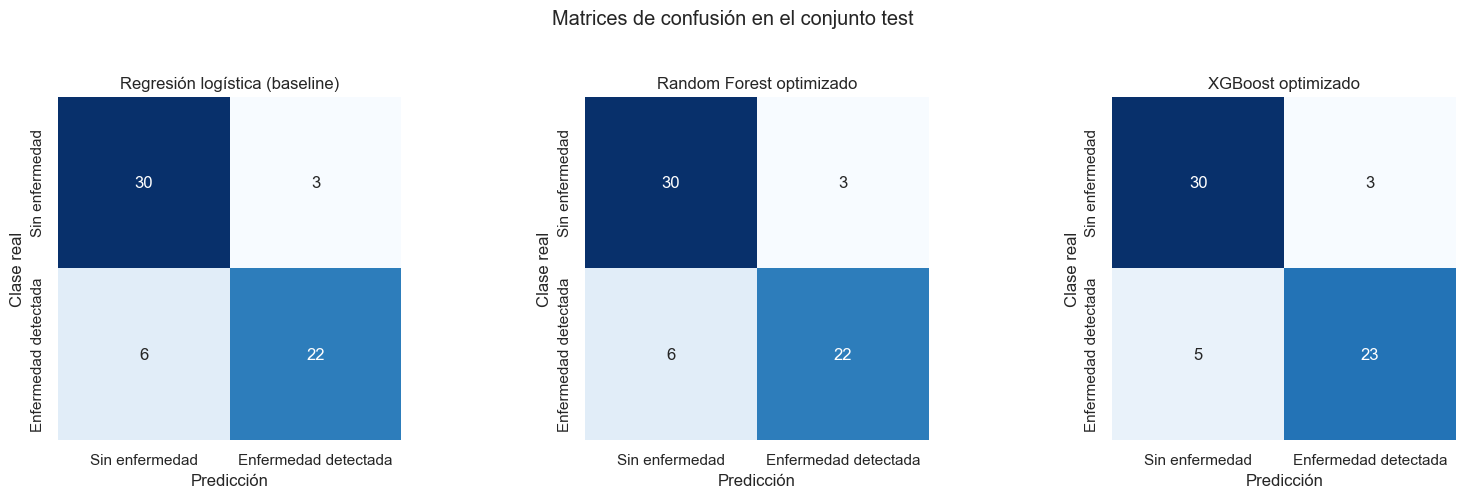

In [ ]:
figura, ejes = plt.subplots(1, 3, figsize=(16, 4.8))
for eje, (nombre_modelo, resultados) in zip(ejes, resultados_test.items()):
    sns.heatmap(
        resultados["matriz_confusion"],
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=nombres_clase,
        yticklabels=nombres_clase,
        ax=eje,
    )
    eje.set_title(nombre_modelo)
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión en el conjunto test", y=1.03)
plt.tight_layout()
plt.show()


## 18. Regresión logística: odds ratios

Para las variables continuas, el odds ratio compara un aumento de **una desviación estándar de entrenamiento** (el escalador del pipeline) manteniendo las demás constantes. Para las variables categóricas, se calcula el contraste de cada categoría frente al primer nivel aprendido por One-Hot Encoder. OR > 1 indica mayores odds estimadas de la clase positiva; OR < 1, menores odds. No son cambios de probabilidad, efectos causales ni pruebas de significación; el modelo tiene regularización y aquí no se calculan intervalos de confianza.


In [ ]:
pasos_logisticos = modelo_logistico_test.named_steps["preprocesamiento"]
clasificador_logistico = modelo_logistico_test.named_steps["clasificador"]
nombres_transformados_logisticos = pasos_logisticos.get_feature_names_out().tolist()
coeficientes_logisticos = clasificador_logistico.coef_[0]
escalador_ajustado = (
    pasos_logisticos.named_transformers_["numericas"].named_steps["escalador"]
)
filas_odds = []

for posicion, variable in enumerate(variables_cuantitativas):
    nombre_transformado = f"numericas__{variable}"
    indice = nombres_transformados_logisticos.index(nombre_transformado)
    coeficiente = coeficientes_logisticos[indice]
    filas_odds.append(
        {
            "variable": variable,
            "contraste": "Aumento de 1 desviación estándar (entrenamiento)",
            "coeficiente_log_odds": coeficiente,
            "odds_ratio": np.exp(coeficiente),
            "magnitud_log_odds": abs(coeficiente),
        }
    )

codificador_ajustado = (
    pasos_logisticos.named_transformers_["categoricas"].named_steps["one_hot"]
)
for variable, niveles in zip(variables_categoricas, codificador_ajustado.categories_):
    nombres_niveles = [f"categoricas__{nombre}" for nombre in codificador_ajustado.get_feature_names_out(variables_categoricas)]
    nombres_variable = [
        f"categoricas__{variable}_{nivel}" for nivel in niveles
    ]
    indices = [nombres_transformados_logisticos.index(nombre) for nombre in nombres_variable]
    coeficientes = coeficientes_logisticos[indices]
    coeficiente_referencia = coeficientes[0]
    for nivel, coeficiente in zip(niveles[1:], coeficientes[1:]):
        contraste = coeficiente - coeficiente_referencia
        filas_odds.append(
            {
                "variable": variable,
                "contraste": f"{nivel} frente a referencia {niveles[0]}",
                "coeficiente_log_odds": contraste,
                "odds_ratio": np.exp(contraste),
                "magnitud_log_odds": abs(contraste),
            }
        )

odds_ratios_logisticos = pd.DataFrame(filas_odds).sort_values(
    "magnitud_log_odds", ascending=False
)
print("Odds ratios; las variables continuas se expresan por 1 desviación estándar de entrenamiento:")
display(odds_ratios_logisticos.drop(columns="magnitud_log_odds").round(3))
print("\nVariables con mayores contrastes absolutos de log-odds (asociaciones ajustadas del modelo):")
display(
    odds_ratios_logisticos.groupby("variable", as_index=False)
    .agg(magnitud_log_odds_maxima=("magnitud_log_odds", "max"))
    .sort_values("magnitud_log_odds_maxima", ascending=False)
    .head(10)
    .round(3)
)


Odds ratios; las variables continuas se expresan por 1 desviación estándar de entrenamiento:


,variable,contraste,coeficiente_log_odds,odds_ratio
16,vasos_principales_observados,2.0 frente a referencia 0.0,2.42,11.25
8,tipo_dolor_toracico,4.0 frente a referencia 1.0,1.69,5.40
15,vasos_principales_observados,1.0 frente a referencia 0.0,1.64,5.15
17,vasos_principales_observados,3.0 frente a referencia 0.0,1.41,4.11
19,resultado_prueba_talio,7.0 frente a referencia 3.0,1.31,3.70
5,sexo,1.0 frente a referencia 0.0,0.98,2.66
13,pendiente_segmento_st,2.0 frente a referencia 1.0,0.75,2.12
1,presion_arterial_reposo,Aumento de 1 desviación estándar (entrenamiento),0.41,1.51
3,frecuencia_cardiaca_maxima,Aumento de 1 desviación estándar (entrenamiento),-0.41,0.67
12,angina_inducida_ejercicio,1.0 frente a referencia 0.0,0.40,1.50



Variables con mayores contrastes absolutos de log-odds (asociaciones ajustadas del modelo):


,variable,magnitud_log_odds_maxima
12,vasos_principales_observados,2.42
11,tipo_dolor_toracico,1.69
9,resultado_prueba_talio,1.31
10,sexo,0.98
6,pendiente_segmento_st,0.75
7,presion_arterial_reposo,0.41
4,frecuencia_cardiaca_maxima,0.41
0,angina_inducida_ejercicio,0.40
8,resultado_electrocardiograma_reposo,0.40
2,depresion_st_ejercicio,0.29


### Interpretación narrativa de los odds ratios\n
\n
Esta celda usa los contrastes positivos calculados para la regresión logística. Expresa las odds como odds (no como probabilidad), muestra las categorías de referencia y limita las recomendaciones a orientación general no diagnóstica.\n

In [ ]:
from IPython.display import Markdown, display

etiquetas_odds = {
    "sexo": {0: "Mujer", 1: "Hombre"},
    "tipo_dolor_toracico": {
        1: "Angina típica",
        2: "Angina atípica",
        3: "Dolor no anginoso",
        4: "Sin síntomas de angina",
    },
    "glucosa_ayunas_alta": {
        0: "Glucosa ≤ 120 mg/dl",
        1: "Glucosa > 120 mg/dl",
    },
    "resultado_electrocardiograma_reposo": {
        0: "Normal",
        1: "Alteración de ondas ST-T",
        2: "Posible/probable hipertrofia ventricular izquierda",
    },
    "angina_inducida_ejercicio": {0: "No", 1: "Sí"},
    "pendiente_segmento_st": {1: "Ascendente", 2: "Plana", 3: "Descendente"},
    "resultado_prueba_talio": {
        3: "Normal",
        6: "Defecto fijo",
        7: "Defecto reversible",
    },
    "vasos_principales_observados": {
        0: "0 vasos",
        1: "1 vaso",
        2: "2 vasos",
        3: "3 vasos",
    },
}

descripciones_odds = {
    "vasos_principales_observados": "número de vasos principales observados por fluoroscopia",
    "tipo_dolor_toracico": "tipo de dolor torácico",
    "resultado_prueba_talio": "resultado de la prueba de talio",
    "sexo": "sexo registrado en este conjunto",
    "pendiente_segmento_st": "pendiente del segmento ST durante ejercicio",
    "angina_inducida_ejercicio": "angina inducida por ejercicio",
}


def etiqueta_contraste(variable, contraste):
    if " frente a referencia " not in contraste:
        return contraste
    nivel, referencia = contraste.split(" frente a referencia ", maxsplit=1)
    try:
        nivel_numero = float(nivel)
        referencia_numero = float(referencia)
    except ValueError:
        return contraste
    etiquetas = etiquetas_odds.get(variable, {})

    def mostrar_nivel(numero):
        entero = int(numero) if numero.is_integer() else numero
        return etiquetas.get(entero, str(entero))

    return f"{mostrar_nivel(nivel_numero)} frente a {mostrar_nivel(referencia_numero)}"


contrastes_positivos = odds_ratios_logisticos.loc[
    (odds_ratios_logisticos["coeficiente_log_odds"] > 0)
    & (odds_ratios_logisticos["odds_ratio"] > 1)
].copy()
if contrastes_positivos.empty:
    display(
        Markdown(
            "El modelo no presenta contrastes con odds ratio superior a 1; "
            "no se puede construir una lista de variables que aumenten las odds."
        )
    )
else:
    top_por_variable = (
        contrastes_positivos.sort_values("coeficiente_log_odds", ascending=False)
        .drop_duplicates("variable")
        .head(3)
    )
    parrafos = [
        "### ¿Cómo leer estas cifras?",
        (
            "El modelo estima la **odds** de enfermedad frente a no enfermedad, "
            "manteniendo constantes las demás variables incluidas. Las odds son "
            "la razón entre la probabilidad de enfermedad y la de no enfermedad; "
            "un OR no significa que la probabilidad se multiplique por ese número. "
            "Por ejemplo, OR = 2,67 significa odds estimadas 2,67 veces mayores "
            "(167 % mayores), no 2,67 veces más probabilidad. Son asociaciones "
            "del modelo, no causas ni diagnósticos individuales."
        ),
        "### Las tres variables con mayor contraste positivo en esta regresión logística",
    ]
    for numero, (_, fila) in enumerate(top_por_variable.iterrows(), start=1):
        variable = fila["variable"]
        contraste = etiqueta_contraste(variable, fila["contraste"])
        odds_ratio = float(fila["odds_ratio"])
        aumento_porcentual = (odds_ratio - 1) * 100
        descripcion = descripciones_odds.get(variable, variable.replace("_", " "))
        if " frente a " in contraste:
            comparacion = f"la categoría **{contraste}**"
        elif contraste.startswith("Aumento de 1 desviación estándar"):
            comparacion = "un aumento de una desviación estándar respecto a la media de entrenamiento"
        else:
            comparacion = f"el contraste **{contraste}**"
        parrafos.append(
            f"{numero}. **{variable.replace('_', ' ').capitalize()}** ({descripcion}): "
            f"al comparar {comparacion}, el modelo estima odds de enfermedad "
            f"**{odds_ratio:.2f} veces mayores** que en la categoría de referencia "
            f"({aumento_porcentual:.0f} % más de odds), ajustando por las demás "
            "variables del modelo."
        )
    parrafos.extend(
        [
            "### Lectura conjunta y cautelas",
            (
                "En este ajuste, las señales positivas más marcadas corresponden a "
                + ", ".join(f"**{fila['variable'].replace('_', ' ')}**" for _, fila in top_por_variable.iterrows())
                + ". Esto describe cómo el modelo separa los datos de esta muestra; "
                "no demuestra que esas características provoquen la enfermedad. "
                "Los contrastes categóricos dependen de su categoría de referencia "
                "y los continuos se expresan por una desviación estándar. Las variables "
                "están relacionadas entre sí y el conjunto es pequeño, por lo que "
                "el orden puede cambiar en otras muestras."
            ),
            "### Orientación general de salud (no sustituye atención médica)",
            (
                "- **Dolor torácico o angina:** un dolor nuevo, intenso o persistente, "
                "especialmente con falta de aire, sudoración, náuseas o desmayo, requiere "
                "atención urgente. No intentes tratarlo solo ni conduzcas si sospechas "
                "una urgencia.\n"
                "- **Presión arterial, colesterol y glucosa:** conviene medirlos y "
                "revisarlos con profesionales sanitarios; sigue el plan prescrito y "
                "no suspendas medicación por cuenta propia.\n"
                "- **Hábitos generales:** no fumar, alimentación equilibrada, actividad "
                "física adaptada y progresiva, sueño suficiente y seguimiento clínico "
                "pueden contribuir a la salud cardiovascular. Consulta antes de hacer "
                "cambios importantes si tienes síntomas o una condición médica.\n"
                "- **Sexo, resultado de talio y vasos observados** no son síntomas que "
                "la persona pueda cambiar. Son datos demográficos o resultados de "
                "pruebas: deben interpretarse con un profesional, no como objetivos "
                "de conducta."
            ),
        ]
    )
    display(Markdown("\n\n".join(parrafos)))
    print("Contrastes positivos mostrados:")
    display(
        top_por_variable[
            ["variable", "contraste", "odds_ratio", "coeficiente_log_odds"]
        ].assign(
            contraste=lambda tabla: [
                etiqueta_contraste(fila["variable"], fila["contraste"])
                for _, fila in tabla.iterrows()
            ]
        ).round(3)
    )


### ¿Cómo leer estas cifras?

El modelo estima la **odds** de enfermedad frente a no enfermedad, manteniendo constantes las demás variables incluidas. Las odds son la razón entre la probabilidad de enfermedad y la de no enfermedad; un OR no significa que la probabilidad se multiplique por ese número. Por ejemplo, OR = 2,67 significa odds estimadas 2,67 veces mayores (167 % mayores), no 2,67 veces más probabilidad. Son asociaciones del modelo, no causas ni diagnósticos individuales.

### Las tres variables con mayor contraste positivo en esta regresión logística

1. **Vasos principales observados** (número de vasos principales observados por fluoroscopia): al comparar la categoría **2 vasos frente a 0 vasos**, el modelo estima odds de enfermedad **11.25 veces mayores** que en la categoría de referencia (1025 % más de odds), ajustando por las demás variables del modelo.

2. **Tipo dolor toracico** (tipo de dolor torácico): al comparar la categoría **Sin síntomas de angina frente a Angina típica**, el modelo estima odds de enfermedad **5.40 veces mayores** que en la categoría de referencia (440 % más de odds), ajustando por las demás variables del modelo.

3. **Resultado prueba talio** (resultado de la prueba de talio): al comparar la categoría **Defecto reversible frente a Normal**, el modelo estima odds de enfermedad **3.70 veces mayores** que en la categoría de referencia (270 % más de odds), ajustando por las demás variables del modelo.

### Lectura conjunta y cautelas

En este ajuste, las señales positivas más marcadas corresponden a **vasos principales observados**, **tipo dolor toracico**, **resultado prueba talio**. Esto describe cómo el modelo separa los datos de esta muestra; no demuestra que esas características provoquen la enfermedad. Los contrastes categóricos dependen de su categoría de referencia y los continuos se expresan por una desviación estándar. Las variables están relacionadas entre sí y el conjunto es pequeño, por lo que el orden puede cambiar en otras muestras.

### Orientación general de salud (no sustituye atención médica)

- **Dolor torácico o angina:** un dolor nuevo, intenso o persistente, especialmente con falta de aire, sudoración, náuseas o desmayo, requiere atención urgente. No intentes tratarlo solo ni conduzcas si sospechas una urgencia.
- **Presión arterial, colesterol y glucosa:** conviene medirlos y revisarlos con profesionales sanitarios; sigue el plan prescrito y no suspendas medicación por cuenta propia.
- **Hábitos generales:** no fumar, alimentación equilibrada, actividad física adaptada y progresiva, sueño suficiente y seguimiento clínico pueden contribuir a la salud cardiovascular. Consulta antes de hacer cambios importantes si tienes síntomas o una condición médica.
- **Sexo, resultado de talio y vasos observados** no son síntomas que la persona pueda cambiar. Son datos demográficos o resultados de pruebas: deben interpretarse con un profesional, no como objetivos de conducta.

Contrastes positivos mostrados:


,variable,contraste,odds_ratio,coeficiente_log_odds
16,vasos_principales_observados,2 vasos frente a 0 vasos,11.25,2.42
8,tipo_dolor_toracico,Sin síntomas de angina frente a Angina típica,5.40,1.69
19,resultado_prueba_talio,Defecto reversible frente a Normal,3.70,1.31


## 19. Random Forest: interpretación global con SHAP

SHAP atribuye a las variables contribuciones a la salida del modelo. Se explica la clase positiva y se agregan las columnas one-hot por variable original para que el ranking sea legible. La importancia es una explicación del modelo, no evidencia causal. Se usa un fondo de entrenamiento y los datos de test solo para explicar las predicciones ya evaluadas; no se cambia el modelo ni los hiperparámetros.


In [ ]:
import shap

preprocesador_rf = modelo_random_forest_optimizado.named_steps["preprocesamiento"]
clasificador_rf = modelo_random_forest_optimizado.named_steps["clasificador"]
matriz_rf_entrenamiento = preprocesador_rf.transform(caracteristicas_entrenamiento)
matriz_rf_test = preprocesador_rf.transform(caracteristicas_test)
if hasattr(matriz_rf_entrenamiento, "toarray"):
    matriz_rf_entrenamiento = matriz_rf_entrenamiento.toarray()
if hasattr(matriz_rf_test, "toarray"):
    matriz_rf_test = matriz_rf_test.toarray()
nombres_features_rf = preprocesador_rf.get_feature_names_out()
fondo_rf = matriz_rf_entrenamiento[: min(80, len(matriz_rf_entrenamiento))]
explicador_rf = shap.TreeExplainer(
    clasificador_rf,
    data=fondo_rf,
    feature_perturbation="interventional",
    model_output="probability",
)
explicaciones_rf = explicador_rf(matriz_rf_test)
valores_shap_rf = np.asarray(explicaciones_rf.values)
if valores_shap_rf.ndim == 3:
    valores_shap_rf = valores_shap_rf[:, :, 1]
if valores_shap_rf.shape != matriz_rf_test.shape:
    raise ValueError(
        f"Forma inesperada de SHAP para RF: {valores_shap_rf.shape}; "
        f"se esperaba {matriz_rf_test.shape}."
    )

def agrupar_nombre_feature(nombre):
    nombre_limpio = nombre.split("__", 1)[1]
    for variable in variables_categoricas:
        if nombre_limpio == variable or nombre_limpio.startswith(f"{variable}_"):
            return variable
    return nombre_limpio


mapa_features_originales_rf = [
    agrupar_nombre_feature(nombre) for nombre in nombres_features_rf
]
importancia_shap_rf = (
    pd.DataFrame(np.abs(valores_shap_rf), columns=mapa_features_originales_rf)
    .T.groupby(level=0)
    .sum()
    .mean(axis=1)
    .sort_values(ascending=False)
    .rename("media_absoluta_SHAP")
    .to_frame()
)
display(importancia_shap_rf.head(10).round(4))


,media_absoluta_SHAP
tipo_dolor_toracico,0.10
resultado_prueba_talio,0.10
vasos_principales_observados,0.08
angina_inducida_ejercicio,0.04
depresion_st_ejercicio,0.03
pendiente_segmento_st,0.03
frecuencia_cardiaca_maxima,0.03
edad,0.02
sexo,0.01
resultado_electrocardiograma_reposo,0.01


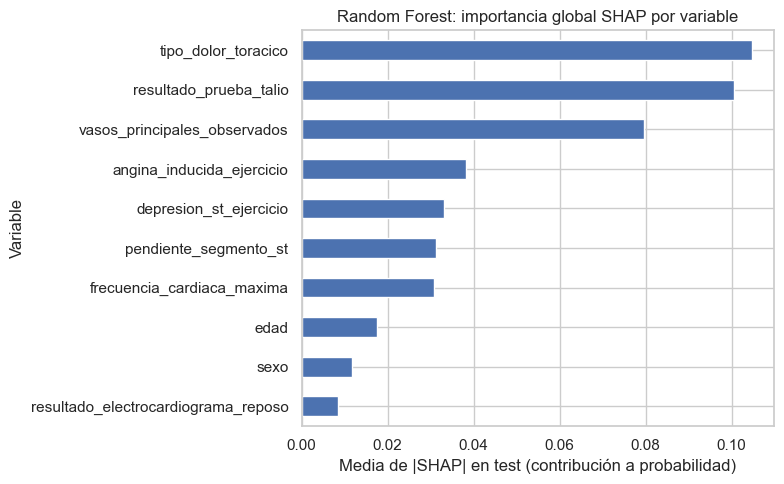

In [ ]:
importancia_shap_rf.head(10).sort_values("media_absoluta_SHAP").plot.barh(
    figsize=(8, 5),
    legend=False,
    color=sns.color_palette("deep")[0],
)
plt.title("Random Forest: importancia global SHAP por variable")
plt.xlabel("Media de |SHAP| en test (contribución a probabilidad)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


### Random Forest: explicación local con LIME

Se explicará una observación positiva del test (seleccionada sin alterar el modelo). LIME aproxima localmente la predicción; sus pesos dependen de la observación y de la vecindad sintética, por lo que no deben confundirse con efectos globales o causales.


In [ ]:
from lime.lime_tabular import LimeTabularExplainer

def preparar_datos_lime():
    entrenamiento_lime = caracteristicas_entrenamiento.copy()
    niveles_lime = {}
    indices_categoricos_lime = [
        caracteristicas_entrenamiento.columns.get_loc(variable)
        for variable in variables_categoricas
    ]
    for variable in variables_cuantitativas:
        mediana_entrenamiento = entrenamiento_lime[variable].median()
        entrenamiento_lime[variable] = entrenamiento_lime[variable].fillna(
            mediana_entrenamiento
        )
    for variable in variables_categoricas:
        niveles = sorted(caracteristicas_entrenamiento[variable].dropna().unique())
        if not niveles:
            raise ValueError(f"No hay niveles de entrenamiento para {variable}.")
        moda_entrenamiento = caracteristicas_entrenamiento[variable].mode().iloc[0]
        entrenamiento_lime[variable] = entrenamiento_lime[variable].fillna(
            moda_entrenamiento
        )
        niveles_lime[variable] = niveles
        codigos = {nivel: codigo for codigo, nivel in enumerate(niveles)}
        entrenamiento_lime[variable] = entrenamiento_lime[variable].map(codigos)
    return entrenamiento_lime, niveles_lime, indices_categoricos_lime


def explicar_instancia_lime(modelo, nombre_modelo, semilla_lime):
    datos_lime, niveles_lime, indices_lime = preparar_datos_lime()
    indices_explicables = []
    for indice, fila in caracteristicas_test.iterrows():
        if all(
            pd.isna(fila[variable]) or fila[variable] in niveles_lime[variable]
            for variable in variables_categoricas
        ):
            indices_explicables.append(indice)
    candidatos_positivos = [
        indice
        for indice in indices_explicables
        if objetivo_test.loc[indice] == 1
    ]
    if not candidatos_positivos:
        raise ValueError("No hay una observación positiva de test explicable por LIME.")
    indice_instancia = candidatos_positivos[0]

    instancia = caracteristicas_test.loc[indice_instancia].copy()
    instancia_codificada = instancia.copy()
    for variable in variables_cuantitativas:
        if pd.isna(instancia_codificada[variable]):
            instancia_codificada[variable] = caracteristicas_entrenamiento[
                variable
            ].median()
    decodificadores = {}
    for variable in variables_categoricas:
        niveles = niveles_lime[variable]
        moda_entrenamiento = caracteristicas_entrenamiento[variable].mode().iloc[0]
        valor = instancia_codificada[variable]
        if pd.isna(valor):
            valor = moda_entrenamiento
        codigos = {nivel: codigo for codigo, nivel in enumerate(niveles)}
        decodificadores[variable] = niveles
        instancia_codificada[variable] = codigos[valor]

    nombres_columnas = caracteristicas_entrenamiento.columns.tolist()

    def predecir_lime(muestras):
        muestras_originales = pd.DataFrame(muestras, columns=nombres_columnas)
        for variable in variables_categoricas:
            niveles = decodificadores[variable]
            codigos = np.rint(muestras_originales[variable]).astype(int)
            if ((codigos < 0) | (codigos >= len(niveles))).any():
                raise ValueError(f"LIME generó un código categórico inválido para {variable}.")
            muestras_originales[variable] = codigos.map(
                {codigo: nivel for codigo, nivel in enumerate(niveles)}
            )
        return modelo.predict_proba(muestras_originales)

    nombres_categorias = {
        caracteristicas_entrenamiento.columns.get_loc(variable): [
            str(nivel) for nivel in niveles_lime[variable]
        ]
        for variable in variables_categoricas
    }
    explicador_lime = LimeTabularExplainer(
        training_data=datos_lime.to_numpy(dtype=float),
        feature_names=nombres_columnas,
        class_names=["Sin enfermedad", "Enfermedad detectada"],
        categorical_features=indices_lime,
        categorical_names=nombres_categorias,
        mode="classification",
        discretize_continuous=True,
        random_state=semilla_lime,
    )
    explicacion_local = explicador_lime.explain_instance(
        data_row=instancia_codificada.to_numpy(dtype=float),
        predict_fn=predecir_lime,
        labels=(1,),
        num_features=len(nombres_columnas),
        num_samples=2_000,
    )
    prediccion = int(modelo.predict(instancia.to_frame().T)[0])
    probabilidad = float(modelo.predict_proba(instancia.to_frame().T)[0, 1])
    print(
        f"{nombre_modelo} — fila test {indice_instancia}; "
        f"diagnóstico real={int(objetivo_test.loc[indice_instancia])}; "
        f"predicción={prediccion}; P(enfermedad)={probabilidad:.3f}"
    )
    display(
        pd.DataFrame(
            explicacion_local.as_list(label=1),
            columns=["regla_local", "peso_LIME"],
        )
    )
    return explicacion_local


explicacion_lime_rf = explicar_instancia_lime(
    modelo_random_forest_optimizado,
    "Random Forest",
    SEMILLA,
)


Random Forest — fila test 168; diagnóstico real=1; predicción=1; P(enfermedad)=0.644


,regla_local,peso_LIME
0,tipo_dolor_toracico=4,0.19
1,resultado_prueba_talio=7.0,0.19
2,vasos_principales_observados=0.0,-0.17
3,angina_inducida_ejercicio=1,0.08
4,pendiente_segmento_st=1,-0.06
5,depresion_st_ejercicio <= 0.00,-0.06
6,edad <= 48.25,-0.03
7,sexo=1,0.03
8,152.00 < frecuencia_cardiaca_maxima <= 166.75,-0.02
9,colesterol_serico > 276.75,0.01


## 20. XGBoost: interpretación global con SHAP

Se usa el mismo enfoque de SHAP y la misma escala de probabilidad de la clase positiva. Las variables one-hot se agregan por predictor original; la explicación no se utiliza para volver a ajustar el modelo.


In [ ]:
preprocesador_xgb = modelo_xgboost_optimizado.named_steps["preprocesamiento"]
clasificador_xgb = modelo_xgboost_optimizado.named_steps["clasificador"]
matriz_xgb_entrenamiento = preprocesador_xgb.transform(caracteristicas_entrenamiento)
matriz_xgb_test = preprocesador_xgb.transform(caracteristicas_test)
if hasattr(matriz_xgb_entrenamiento, "toarray"):
    matriz_xgb_entrenamiento = matriz_xgb_entrenamiento.toarray()
if hasattr(matriz_xgb_test, "toarray"):
    matriz_xgb_test = matriz_xgb_test.toarray()
nombres_features_xgb = preprocesador_xgb.get_feature_names_out()
fondo_xgb = matriz_xgb_entrenamiento[: min(80, len(matriz_xgb_entrenamiento))]
explicador_xgb = shap.TreeExplainer(
    clasificador_xgb,
    data=fondo_xgb,
    feature_perturbation="interventional",
    model_output="probability",
)
explicaciones_xgb = explicador_xgb(matriz_xgb_test)
valores_shap_xgb = np.asarray(explicaciones_xgb.values)
if valores_shap_xgb.ndim == 3:
    valores_shap_xgb = valores_shap_xgb[:, :, 1]
if valores_shap_xgb.shape != matriz_xgb_test.shape:
    raise ValueError(
        f"Forma inesperada de SHAP para XGBoost: {valores_shap_xgb.shape}; "
        f"se esperaba {matriz_xgb_test.shape}."
    )

mapa_features_originales_xgb = [
    agrupar_nombre_feature(nombre) for nombre in nombres_features_xgb
]
importancia_shap_xgb = (
    pd.DataFrame(np.abs(valores_shap_xgb), columns=mapa_features_originales_xgb)
    .T.groupby(level=0)
    .sum()
    .mean(axis=1)
    .sort_values(ascending=False)
    .rename("media_absoluta_SHAP")
    .to_frame()
)
display(importancia_shap_xgb.head(10).round(4))


,media_absoluta_SHAP
tipo_dolor_toracico,0.14
vasos_principales_observados,0.12
resultado_prueba_talio,0.11
depresion_st_ejercicio,0.04
frecuencia_cardiaca_maxima,0.04
colesterol_serico,0.04
pendiente_segmento_st,0.03
edad,0.03
sexo,0.03
angina_inducida_ejercicio,0.02


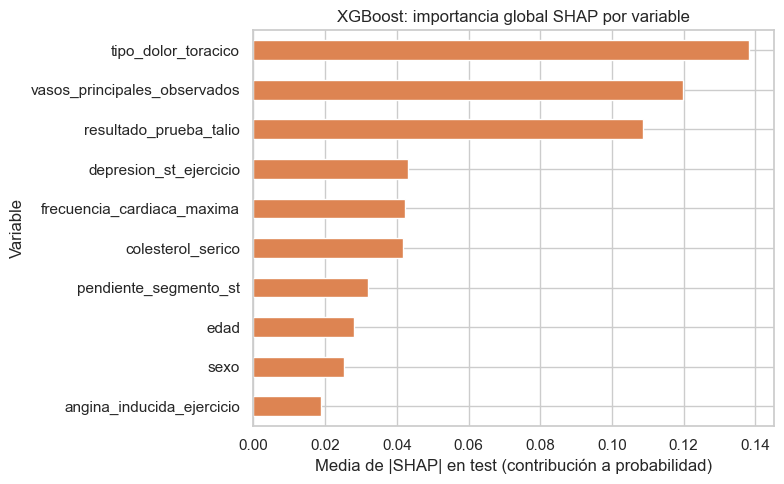

In [ ]:
importancia_shap_xgb.head(10).sort_values("media_absoluta_SHAP").plot.barh(
    figsize=(8, 5),
    legend=False,
    color=sns.color_palette("deep")[1],
)
plt.title("XGBoost: importancia global SHAP por variable")
plt.xlabel("Media de |SHAP| en test (contribución a probabilidad)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


### XGBoost: explicación local con LIME

Se explica la misma observación positiva seleccionada en la celda LIME de Random Forest para facilitar la comparación. LIME es una aproximación local y puede variar según la muestra sintética y la observación escogida.


In [ ]:
explicacion_lime_xgb = explicar_instancia_lime(
    modelo_xgboost_optimizado,
    "XGBoost",
    SEMILLA,
)


XGBoost — fila test 168; diagnóstico real=1; predicción=1; P(enfermedad)=0.773


,regla_local,peso_LIME
0,tipo_dolor_toracico=4,0.30
1,vasos_principales_observados=0.0,-0.30
2,resultado_prueba_talio=7.0,0.22
3,colesterol_serico > 276.75,0.09
4,sexo=1,0.08
5,depresion_st_ejercicio <= 0.00,-0.06
6,pendiente_segmento_st=1,-0.06
7,angina_inducida_ejercicio=1,0.04
8,edad <= 48.25,-0.04
9,152.00 < frecuencia_cardiaca_maxima <= 166.75,-0.03


## 21. Variables más influyentes e interpretación conjunta

La tabla sintetiza el ranking global de SHAP de ambos árboles y los mayores contrastes de odds del modelo logístico. SHAP mide contribución a predicciones de los modelos de árboles; los odds ratios son asociaciones condicionales del baseline. Sus magnitudes **no son comparables entre sí** y ninguna medida implica causalidad. La explicación LIME es local a una sola fila, no un ranking poblacional.


In [ ]:
top_variables_modelos = pd.concat(
    {
        "Regresión logística (máximo |log OR|)": (
            odds_ratios_logisticos.groupby("variable")["magnitud_log_odds"]
            .max()
            .sort_values(ascending=False)
            .head(10)
        ),
        "Random Forest (media |SHAP|)": importancia_shap_rf[
            "media_absoluta_SHAP"
        ].head(10),
        "XGBoost (media |SHAP|)": importancia_shap_xgb[
            "media_absoluta_SHAP"
        ].head(10),
    },
    names=["modelo", "variable"],
).rename("importancia").reset_index()
display(top_variables_modelos)

print("Resumen de los resultados de test:")
display(metricas_test.sort_values("precision", ascending=False).round(3))

print(
    "Interpreta conjuntamente estas tablas: la regresión logística resume "
    "asociaciones mediante odds ratios; SHAP resume contribuciones predictivas "
    "globales de RF y XGBoost; LIME explica una predicción individual. "
    "La importancia puede variar entre modelos y no demuestra causalidad. "
    "Dado el tamaño pequeño del test (61 observaciones), las métricas tienen "
    "incertidumbre y no deben considerarse una validación clínica."
)


,modelo,variable,importancia
0,Regresión logística (máximo |log OR|),vasos_principales_observados,2.42
1,Regresión logística (máximo |log OR|),tipo_dolor_toracico,1.69
2,Regresión logística (máximo |log OR|),resultado_prueba_talio,1.31
3,Regresión logística (máximo |log OR|),sexo,0.98
4,Regresión logística (máximo |log OR|),pendiente_segmento_st,0.75
5,Regresión logística (máximo |log OR|),presion_arterial_reposo,0.41
6,Regresión logística (máximo |log OR|),frecuencia_cardiaca_maxima,0.41
7,Regresión logística (máximo |log OR|),angina_inducida_ejercicio,0.40
8,Regresión logística (máximo |log OR|),resultado_electrocardiograma_reposo,0.40
9,Regresión logística (máximo |log OR|),depresion_st_ejercicio,0.29


Resumen de los resultados de test:


,precision,sensibilidad,especificidad,f1,exactitud_balanceada,auc_roc
modelo,,,,,,
XGBoost optimizado,0.89,0.82,0.91,0.85,0.86,0.92
Regresión logística (baseline),0.88,0.79,0.91,0.83,0.85,0.94
Random Forest optimizado,0.88,0.79,0.91,0.83,0.85,0.92


Interpreta conjuntamente estas tablas: la regresión logística resume asociaciones mediante odds ratios; SHAP resume contribuciones predictivas globales de RF y XGBoost; LIME explica una predicción individual. La importancia puede variar entre modelos y no demuestra causalidad. Dado el tamaño pequeño del test (61 observaciones), las métricas tienen incertidumbre y no deben considerarse una validación clínica.


## 22. Demostración interactiva educativa: salida probabilística del modelo

La interfaz permite introducir las 13 variables del conjunto y consultar la salida `predict_proba` de los tres modelos ajustados. Por defecto se selecciona el candidato con mayor precisión media de validación cruzada en entrenamiento; puedes cambiar el modelo desde el selector. Se emplea el pipeline completo ya ajustado con entrenamiento: los datos introducidos pasan por las mismas imputaciones, escalado y codificación aprendidos, sin reentrenar ni consultar el test.

> **Solo demostración educativa. No es una herramienta clínica ni un sistema de cribado validado.** El valor mostrado es la puntuación probabilística del modelo, no una probabilidad clínica individual calibrada. El conjunto Cleveland es pequeño, antiguo y no representativo de la población general; el rendimiento fuera de este conjunto no está establecido. No uses este resultado para autodiagnóstico, descartar enfermedad, retrasar asistencia, iniciar o suspender tratamientos. La valoración corresponde a profesionales sanitarios. Ante dolor torácico intenso/nuevo o síntomas urgentes, contacta con los servicios de emergencia locales.

Los campos `vasos_principales_observados` y `resultado_prueba_talio` representan resultados de pruebas médicas, no síntomas ni datos que siempre estén disponibles antes de una evaluación. “Sin dato” se procesa mediante la imputación ya aprendida por el pipeline. No introduzcas identificadores ni información personal.


## Aplicación Streamlit

La interfaz está en `app.py` y no vuelve a entrenar modelos. Ejecuta la siguiente celda una vez después de completar el entrenamiento para guardar el pipeline de Random Forest y, a continuación, inicia la app desde esta carpeta con `streamlit run app.py`. El archivo `modelo_cardio.joblib` contiene el modelo entrenado y no los datos de pacientes.


In [ ]:
from pathlib import Path
import joblib

columnas_numericas_app = variables_cuantitativas
bundle_app = {
    "format_version": 1,
    "model": modelo_random_forest_optimizado,
    "feature_columns": caracteristicas.columns.tolist(),
    "numeric_ranges": {
        variable: {
            "min": float(caracteristicas_entrenamiento[variable].min()),
            "max": float(caracteristicas_entrenamiento[variable].max()),
        }
        for variable in columnas_numericas_app
    },
    "numeric_defaults": {
        variable: float(caracteristicas_entrenamiento[variable].median())
        for variable in columnas_numericas_app
    },
}

ruta_modelo_app = Path("modelo_cardio.joblib")
joblib.dump(bundle_app, ruta_modelo_app, compress=3)
print(f"Pipeline exportado para Streamlit: {ruta_modelo_app}")
